# Privacy CPC Codes by Group: Pooled and Per-Code Yearly Counts in the Sample Firms' Patents, 1999 to 2021

| Item | Description |
|---|---|
| Goal | The 72-code privacy list read through the four groups of `privacy_cpc_codes_clustered_by_claude.csv` (privacy protection; use of personal data; interception by authorities; security). For each group, two figures: the pooled trend, the number of sample-firm patents carrying at least one code of the group in each filing year, and the per-code trends, one small panel per code of the group on a single canvas, as in T4.X.6 but cut by group instead of by twelve. |
| Input | `privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv` (the 72 codes with their group); `Processed/sample_firm_patent_cpc_codes.parquet` (T4.1.2, every CPC code of every sample-firm patent) and `Processed/sample_firm_patents.parquet` (T4.1.1, filing and issue years) in the T4.1 stage folder on scratch. |
| Output | `output/T4.2.5/group_counts_by_filing_year.csv` (one row per group and year, distinct patents), `output/T4.2.5/code_counts_by_filing_year.csv` (one row per code and year), and eight figures `fig_<k>_group_<A..D>_pooled_by_filing_year` and `fig_<k>_group_<A..D>_codes_by_filing_year` as PNG, SVG, and PDF. |
| Unit | A patent. In the pooled figures a patent counts once per group however many of the group's codes it carries; in the per-code panels it counts once per code. |
| Groups | A, privacy protection: PII protection, anonymity, privacy-enhancing cryptography (22 codes). B, use of personal data: tracking, profiling, targeting, monitoring people (14). C, interception by authorities (2). D, security: encryption, access control, secure storage, obfuscation (34). The assignment is the one proposed in the clustered file and can be edited there; this notebook reads whatever it holds. |
| Panel titles | Code, total patents over the period, and the first year a patent carrying the code was granted. KPSS records codes as of grant, so a first grant year well after 1999 marks a code created by a later CPC scheme, whose earlier patents sit under a predecessor code. |
| Style | S3 colors and font on a 9 by 6 inch canvas with 0.5 cm margins, RED lines with markers, a solid BLACK zero line, title and Notes in Markdown around each image, no vertical reference line. The per-code figures depart from the S3 one-panel rule on purpose, as T4.X.6 does, so that a group's codes can be compared side by side; the grid and font size follow the number of codes in the group. |

See `T4.X.6` for the same panels cut by twelve, `T4.X.3` for where each code occurs in KPSS and PatentsView, and `T4.1.2` for the privacy-patent definition.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the period, and the group names

The two roots and the S5 folders; the clustered list from the section folder, the patent files from the T4.1 stage folder on scratch. The short group titles used in figure titles are fixed here against the group labels of the file.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SECTION = Path("X1 - Example of Research Enabled by LLM Pipeline")
NOTEBOOK_SUBFOLDER = NOTEBOOK_SECTION / "X1.2 - Privacy Patents and Topic Relevance - 5 Codes by MM"
NOTEBOOK_NAME = "T4.2.5"  # the identifier names this notebook's output folder
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output" / NOTEBOOK_NAME
T41_PROCESSED = SCRATCH_FOLDER / NOTEBOOK_SECTION / "X1.1 - Privacy Patents and Topic Relevance/Processed"
CLUSTERED_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv"
CODES_FILE = T41_PROCESSED / "sample_firm_patent_cpc_codes.parquet"  # T4.1.2
PATENTS_FILE = T41_PROCESSED / "sample_firm_patents.parquet"  # T4.1.1

PERIOD_START = 1999  # filing years drawn, as in T4.1.2
PERIOD_END = 2021
GROUP_TITLES = {"A": "Privacy Protection", "B": "Use of Personal Data", "C": "Interception by Authorities", "D": "Security"}  # keyed by the group letter in the file
GROUP_WORDS = {"A": "privacy protection: personal data protection, anonymity, and privacy-enhancing cryptography",
               "B": "use of personal data: tracking, profiling, targeting, and monitoring of people",
               "C": "interception of communications by authorities",
               "D": "security: encryption, access control, secure storage, and obfuscation"}
PERIOD_WORDS = f"{PERIOD_START} to {PERIOD_END}"
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in "
          "privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.5


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. The per-code panels use smaller text, scaled to the size of the group.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the grouped list and the patents, and count by group and by code

The clustered file gives each code's group; its letter is the first character of the group label. Every CPC code of every sample-firm patent is joined to the filing and issue years and kept for the period. Per group and year: distinct patents carrying any code of the group. Per code and year: distinct patents carrying the code, with the code's total and first grant year for the panel titles. Both tables are saved.


In [4]:
clustered = pd.read_csv(CLUSTERED_FILE)
clustered["cpc"] = clustered["cpc_display"].str.replace(" ", "", regex=False)
clustered["group_letter"] = clustered["group"].str[0]
assert clustered["cpc"].is_unique and set(clustered["group_letter"]) <= set(GROUP_TITLES)
codes = pd.read_parquet(CODES_FILE, columns=["patent_num", "cpc"])
codes = codes.loc[codes["cpc"].isin(clustered["cpc"])]
patents = pd.read_parquet(PATENTS_FILE, columns=["patent_num", "filing_year", "issue_year"])
codes = codes.merge(patents, on="patent_num", how="inner", validate="many_to_one")
codes = codes.loc[codes["filing_year"].between(PERIOD_START, PERIOD_END)]
codes = codes.merge(clustered[["cpc", "group_letter"]], on="cpc", how="left")
years = list(range(PERIOD_START, PERIOD_END + 1))
group_counts = codes.groupby(["group_letter", "filing_year"])["patent_num"].nunique().unstack(fill_value=0).reindex(index=sorted(GROUP_TITLES), columns=years, fill_value=0)
code_counts = codes.groupby(["cpc", "filing_year"])["patent_num"].nunique().unstack(fill_value=0).reindex(index=clustered["cpc"], columns=years, fill_value=0)
summary = clustered.set_index("cpc")[["cpc_display", "cpc_class", "definition", "group_letter"]].copy()
summary["n_patents"] = code_counts.sum(axis=1).astype(int)
summary = summary.join(codes.groupby("cpc").agg(first_filing_year=("filing_year", "min"), first_grant_year=("issue_year", "min")))
summary = summary.sort_values(["group_letter", "n_patents"], ascending=[True, False])
group_totals = codes.groupby("group_letter")["patent_num"].nunique()
group_counts.stack().rename("n_patents").reset_index().rename(columns={"level_1": "filing_year"}).to_csv(OUTPUT_FOLDER / "group_counts_by_filing_year.csv", index=False)
code_counts.loc[summary.index].stack().rename("n_patents").reset_index().rename(columns={"level_1": "filing_year"}).merge(summary[["group_letter"]], left_on="cpc", right_index=True).to_csv(OUTPUT_FOLDER / "code_counts_by_filing_year.csv", index=False)
print(f"Codes: {len(summary)}; patents carrying any listed code in {PERIOD_WORDS}: {codes['patent_num'].nunique():,}")
display(pd.DataFrame({"group": [f"{g}. {GROUP_TITLES[g]}" for g in sorted(GROUP_TITLES)], "codes": summary.groupby("group_letter").size().reindex(sorted(GROUP_TITLES)).to_numpy(),
                      "distinct_patents": group_totals.reindex(sorted(GROUP_TITLES)).fillna(0).astype(int).to_numpy()}))


Codes: 72; patents carrying any listed code in 1999 to 2021: 33,986


,group,codes,distinct_patents
0,A. Privacy Protection,22,6467
1,B. Use of Personal Data,14,7293
2,C. Interception by Authorities,2,182
3,D. Security,34,23266


## Step 5. Figure 1: group A pooled, patents carrying any code of the group by filing year

One RED line with markers, the distinct sample-firm patents filed in each year that carry at least one code of group A; a solid BLACK zero line; no legend. The Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge, measured after drawing. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 1. Sample-Firm Patents Carrying Any Code of Group A, Privacy Protection, by Filing Year, 1999 to 2021**

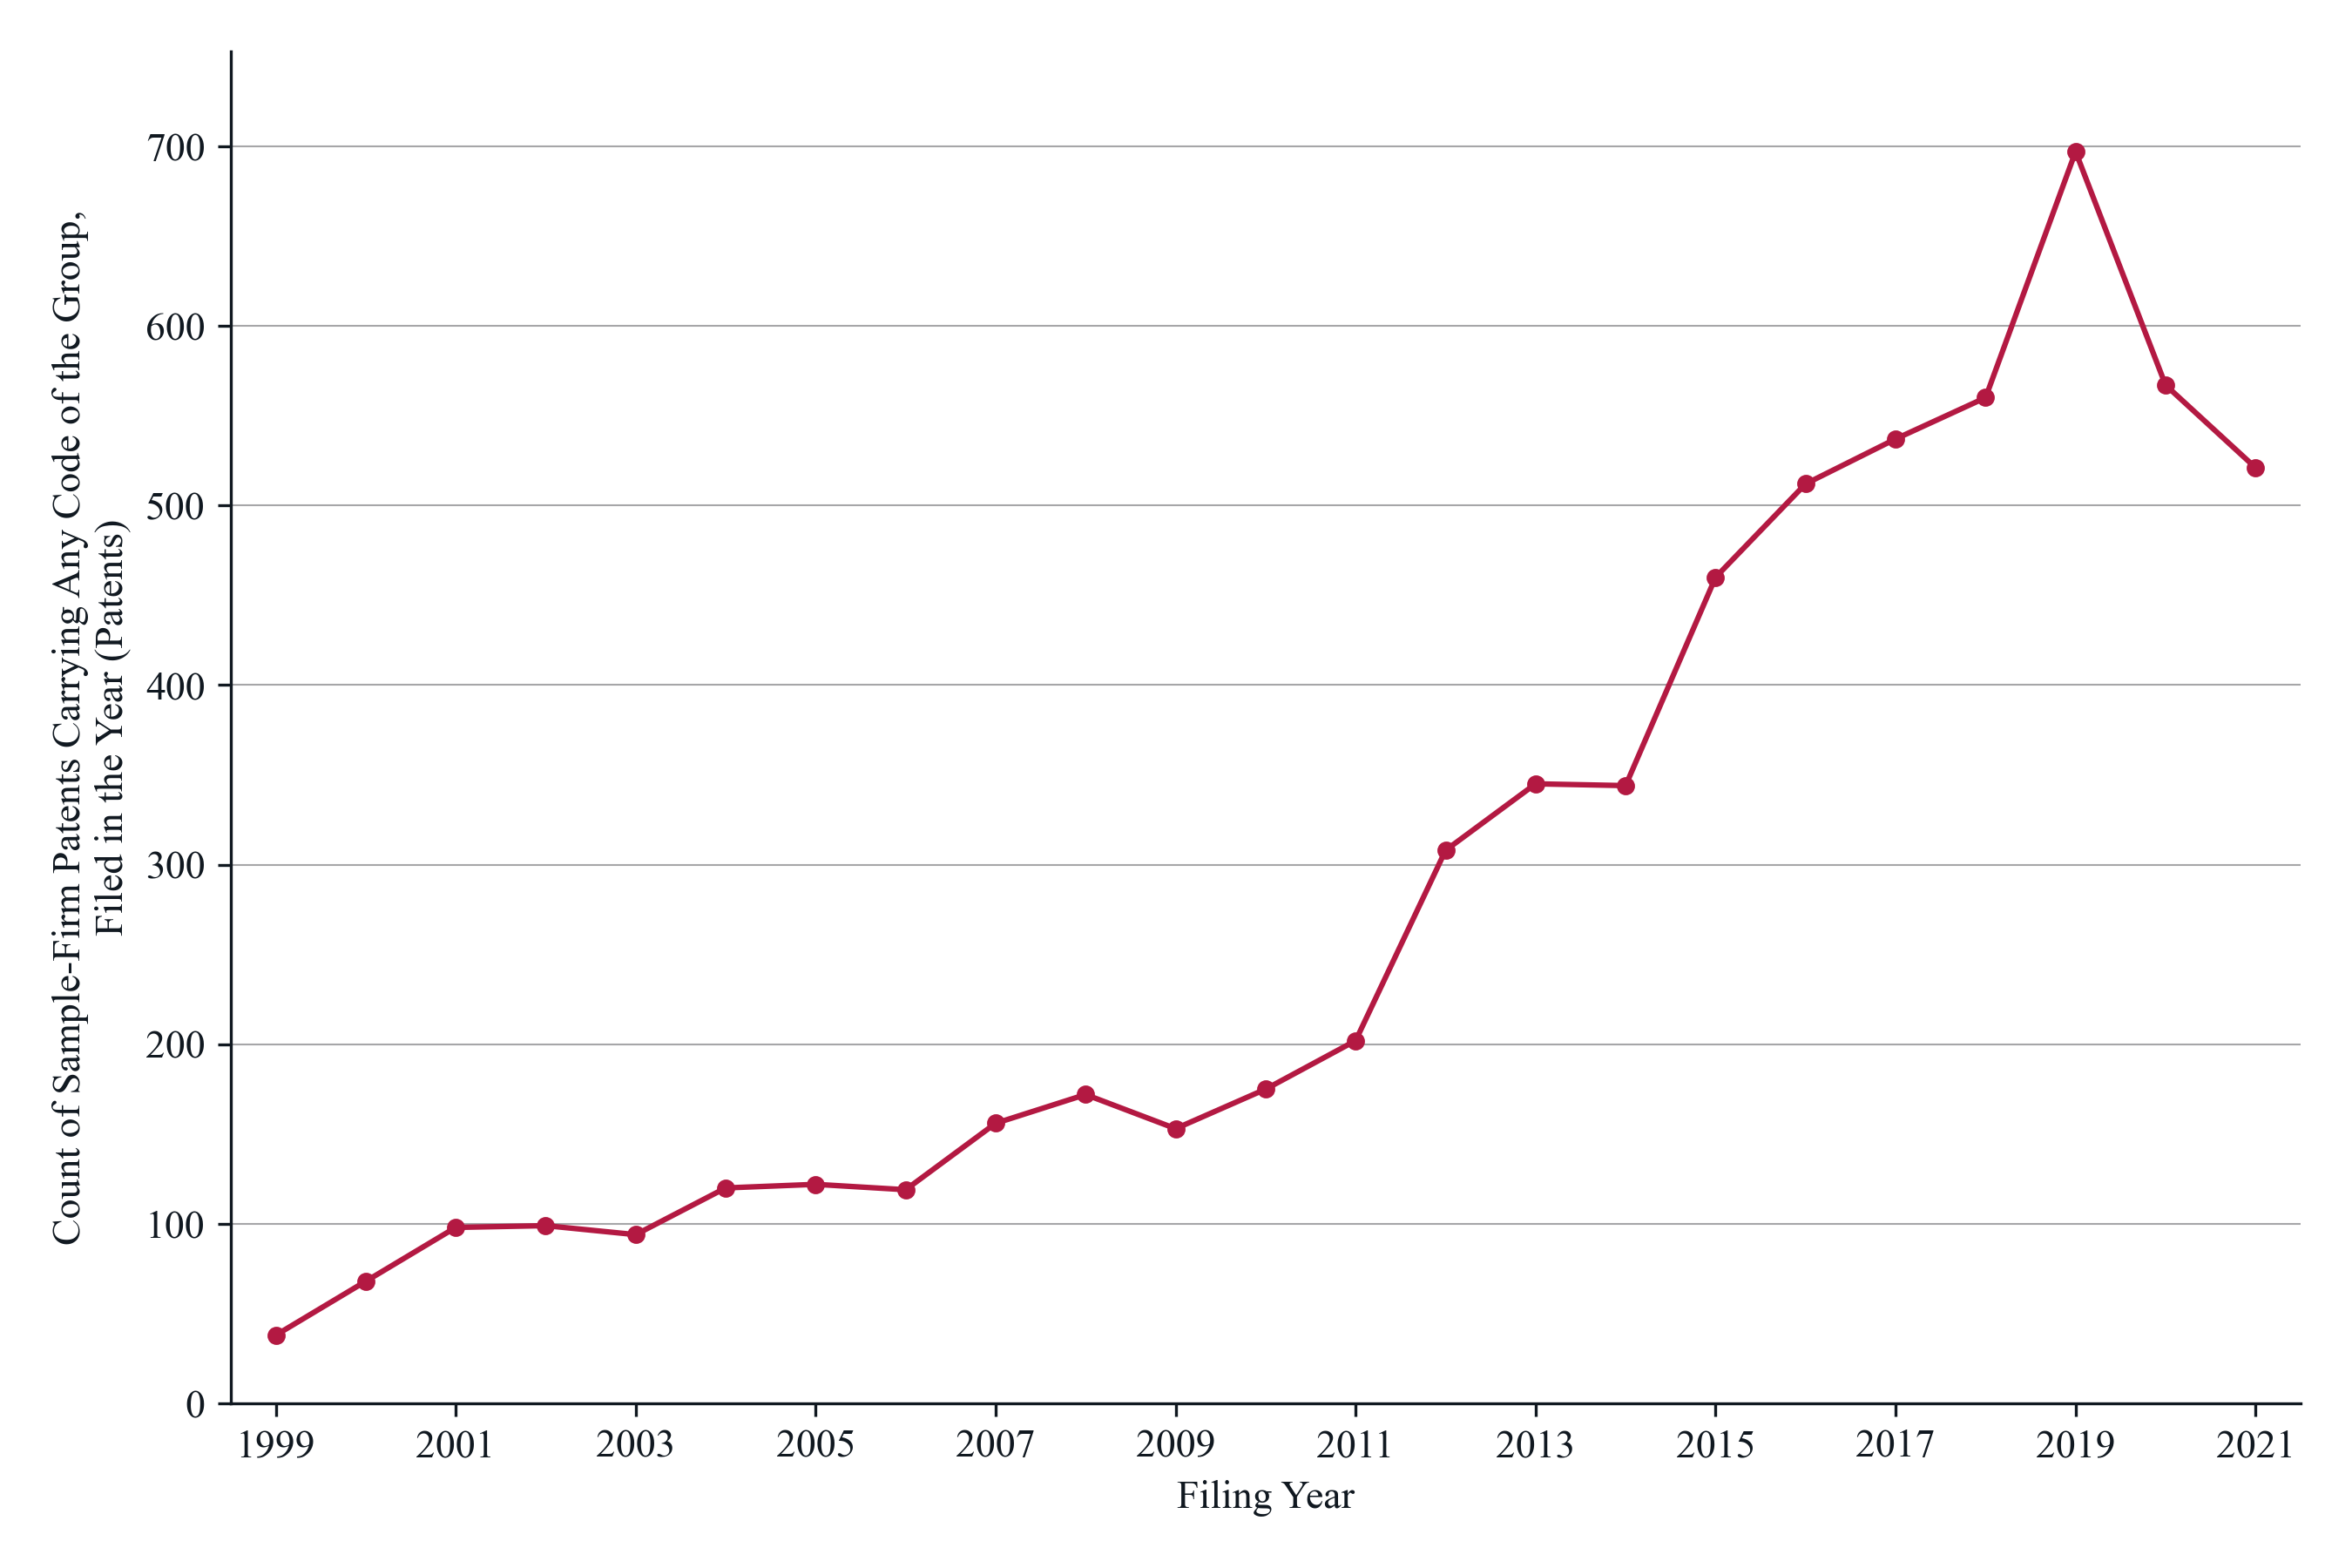

*Notes*: The line is the number of sample-firm KPSS patents filed in each year, 1999 to 2021, that carry at least one of the 22 codes of group A, privacy protection: personal data protection, anonymity, and privacy-enhancing cryptography; a patent counts once however many of the group's codes it carries. 6,467 patents in all, from 38 in 1999 to a peak of 697 in 2019 and 521 in 2021. The group's codes, with their totals: G06F 21/6245 2,124; H04W 12/02 1,519; G06F 21/6254 819; G06Q 20/385 691; G06F 21/6263 383; H04L 63/0407 296; H04L 63/0421 291; H04L 9/008 289; H04L 2209/42 186; H04L 9/3218 184; H04L 63/0414 136; G06Q 20/383 131; G06Q 20/3678 121; H04L 9/3255 87; H04W 8/16 86; H04L 2209/46 76; H04L 9/3221 76; H04L 61/2539 65; H04L 9/3257 46; G06Q 30/0615 45; H04L 2209/50 25; H04W 12/75 7. A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [5]:
figure_number = 1
letter = "A"
figure_name = f"fig_{figure_number}_group_{letter}_pooled_by_filing_year"
title = f"Sample-Firm Patents Carrying Any Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Count of Sample-Firm Patents Carrying Any Code of the Group,\nFiled in the Year (Patents)"
series = group_counts.loc[letter]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.12)
axis.plot(years, series.to_numpy(), color=RED, linewidth=1.5, marker="o", markersize=4, zorder=3)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(series.max(), 1) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
y_title_box = axis.yaxis.label.get_window_extent(renderer)
assert y_title_box.y0 >= margin_pixels - 1 and y_title_box.y1 <= figure.bbox.height - margin_pixels + 1, f"Y-title runs from {y_title_box.y0 / figure.dpi:.2f} to {y_title_box.y1 / figure.dpi:.2f} inches"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

members = summary.loc[summary["group_letter"] == letter]
peak_year = int(series.idxmax())
notes = (f"The line is the number of sample-firm KPSS patents filed in each year, {PERIOD_WORDS}, that carry at least one of the {len(members)} codes of group {letter}, {GROUP_WORDS[letter]}; "
         f"a patent counts once however many of the group's codes it carries. {int(group_totals.get(letter, 0)):,} patents in all, from {int(series.iloc[0]):,} in {PERIOD_START} to a peak of "
         f"{int(series.max()):,} in {peak_year} and {int(series.iloc[-1]):,} in {PERIOD_END}. The group's codes, with their totals: "
         + "; ".join(f"{d} {n:,}" for d, n in zip(members["cpc_display"], members["n_patents"])) +
         ". A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted "
         "patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 6. Figure 2: group A by code, one panel per code of the group

All codes of group A on one canvas, ordered by total, each panel a RED line with markers over the filing years with its own vertical scale, a solid BLACK zero line, and a title with the code, its total, and its first grant year. The grid and font size follow the number of codes. The panel block is positioned after drawing so that it clears the margins and the shared axis titles. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 2. Sample-Firm Patents Carrying Each Code of Group A, Privacy Protection, by Filing Year, 22 Codes, 1999 to 2021**

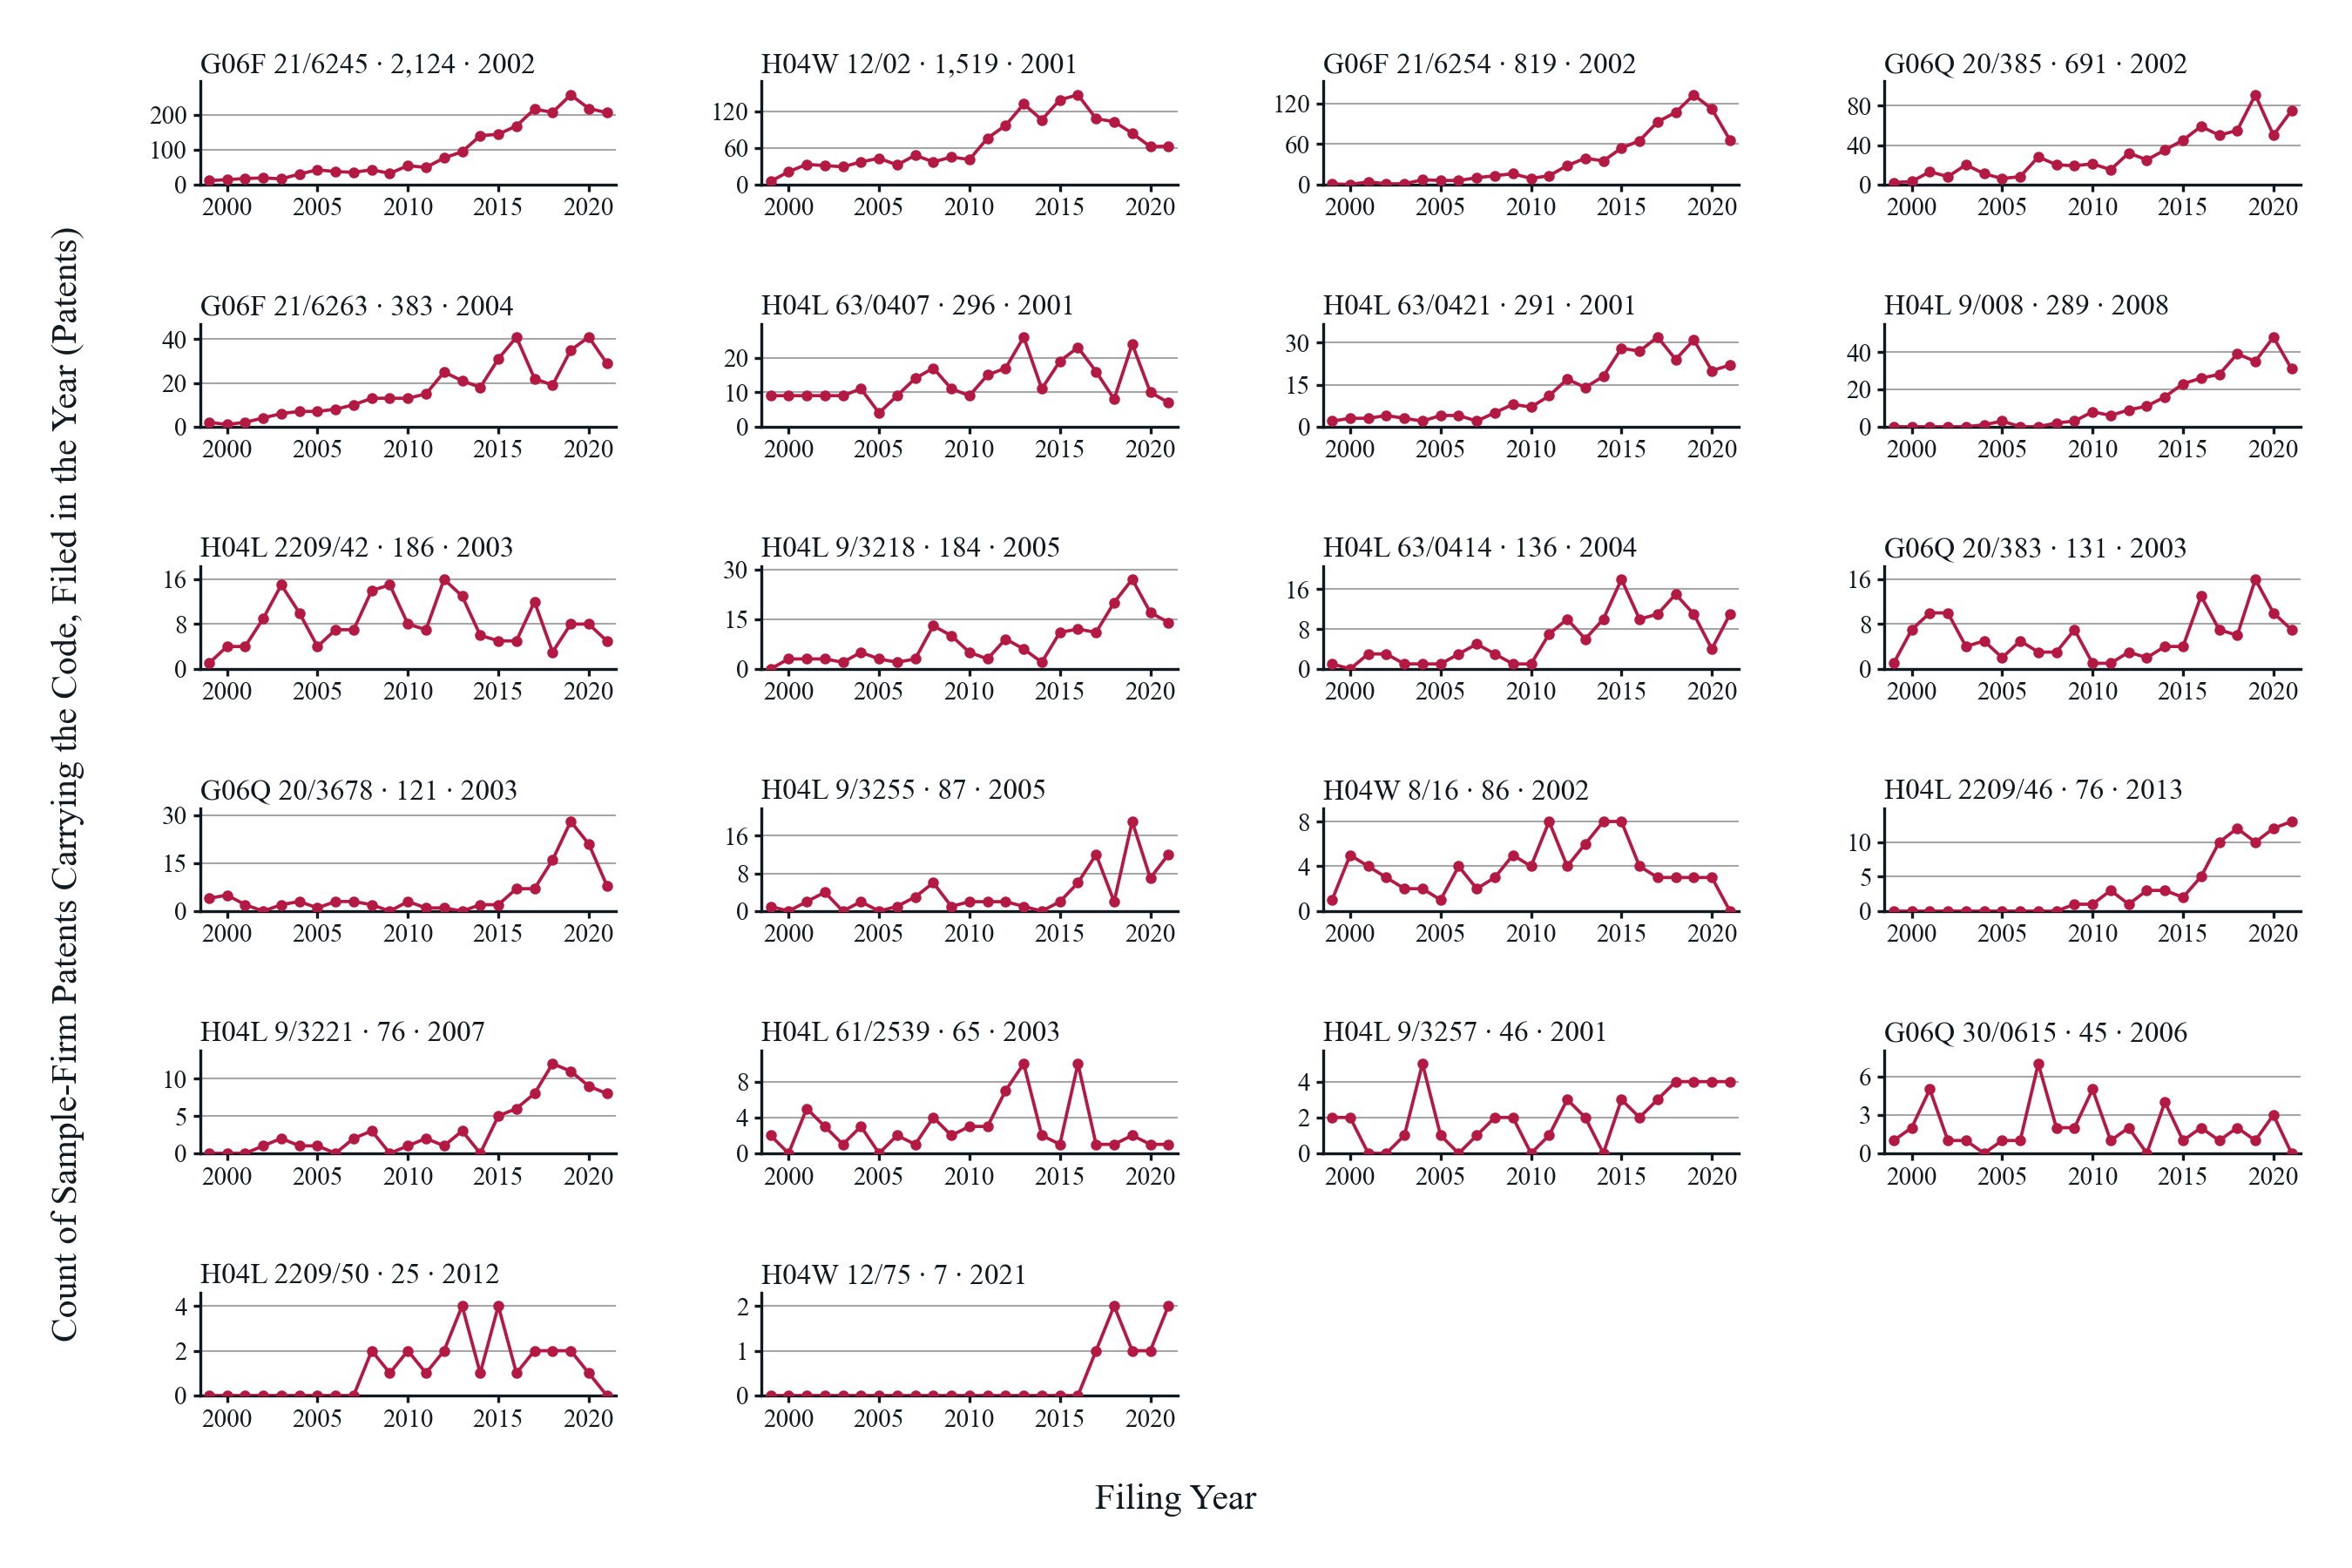

*Notes*: Each panel is one of the 22 codes of group A, privacy protection: personal data protection, anonymity, and privacy-enhancing cryptography, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, by filing year, 1999 to 2021; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. Codes in this group whose first grant is 2015 or later: H04W 12/75 (2021). Codes with no sample-firm patent in the period: none. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [6]:
figure_number = 2
letter = "A"
figure_name = f"fig_{figure_number}_group_{letter}_codes_by_filing_year"
members = summary.loc[summary["group_letter"] == letter]
n = len(members)
columns = 2 if n <= 2 else (4 if n <= 24 else 6)
rows = int(np.ceil(n / columns))
font_size = 7 if columns <= 4 else 6
title = f"Sample-Firm Patents Carrying Each Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {n} Codes, {PERIOD_WORDS}"
figure, axes = plt.subplots(rows, columns, figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), squeeze=False)
figure.subplots_adjust(left=0.085, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.95, bottom=0.11, hspace=0.75 + 0.1 * rows, wspace=0.35)
x_ticks = [2000, 2010, 2020] if columns == 6 else [2000, 2005, 2010, 2015, 2020]
for axis, code in zip(axes.flat, members.index):
    series = code_counts.loc[code]
    axis.plot(years, series.to_numpy(), color=RED, linewidth=0.9, marker="o", markersize=1.5 if columns == 6 else 2, zorder=3)
    axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
    axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
    axis.set_ylim(0, max(series.max(), 1) * 1.15)
    axis.set_xticks(x_ticks)
    axis.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3, integer=True))
    axis.yaxis.set_major_formatter(THOUSANDS)
    axis.tick_params(labelsize=font_size, length=2, pad=1.5)
    first_grant = int(members.loc[code, "first_grant_year"]) if pd.notna(members.loc[code, "first_grant_year"]) else "none"
    axis.set_title(f"{members.loc[code, 'cpc_display']} · {members.loc[code, 'n_patents']:,} · {first_grant}", fontsize=font_size + 1, pad=2.5, loc="left")
    axis.spines[["top", "right"]].set_visible(False)
for axis in list(axes.flat)[n:]:
    axis.set_visible(False)
x_label = figure.supxlabel("Filing Year", fontsize=10, y=MARGIN_INCHES / FIGURE_HEIGHT, va="bottom")
y_label = figure.supylabel("Count of Sample-Firm Patents Carrying the Code, Filed in the Year (Patents)", fontsize=10, x=MARGIN_INCHES / FIGURE_WIDTH, ha="left")
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
# Margins: the panel block is moved so that it clears the top margin, the X-title below, and the Y-title to the left, then checked.
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
gap = 0.3 * margin_pixels
top_overflow = max(b.y1 for b in boxes) - (figure.bbox.height - margin_pixels)
bottom_deficit = x_label.get_window_extent(renderer).y1 + gap - min(b.y0 for b in boxes)
left_deficit = y_label.get_window_extent(renderer).x1 + gap - min(b.x0 for b in boxes)
right_overflow = max(b.x1 for b in boxes) - (figure.bbox.width - margin_pixels)
figure.subplots_adjust(top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height, bottom=figure.subplotpars.bottom + max(bottom_deficit, 0) / figure.bbox.height,
                       left=figure.subplotpars.left + max(left_deficit, 0) / figure.bbox.width, right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width)
figure.canvas.draw()
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
assert min(b.x0 for b in boxes) >= y_label.get_window_extent(renderer).x1 - 1 and max(b.x1 for b in boxes) <= figure.bbox.width - margin_pixels + 1, "panels cross the side margins"
assert max(b.y1 for b in boxes) <= figure.bbox.height - margin_pixels + 1 and min(b.y0 for b in boxes) >= x_label.get_window_extent(renderer).y1 - 1, "panels cross the top margin or the X-title"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

late = [f"{members.loc[c, 'cpc_display']} ({int(members.loc[c, 'first_grant_year'])})" for c in members.index if pd.notna(members.loc[c, "first_grant_year"]) and members.loc[c, "first_grant_year"] >= 2015]
empty = [members.loc[c, "cpc_display"] for c in members.index if members.loc[c, "n_patents"] == 0]
notes = (f"Each panel is one of the {n} codes of group {letter}, {GROUP_WORDS[letter]}, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, "
         f"by filing year, {PERIOD_WORDS}; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a "
         "patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows "
         "nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. "
         f"Codes in this group whose first grant is 2015 or later: {', '.join(late) if late else 'none'}. Codes with no sample-firm patent in the period: {', '.join(empty) if empty else 'none'}. "
         "Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 "
         "firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 7. Figure 3: group B pooled, patents carrying any code of the group by filing year

One RED line with markers, the distinct sample-firm patents filed in each year that carry at least one code of group B; a solid BLACK zero line; no legend. The Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge, measured after drawing. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 3. Sample-Firm Patents Carrying Any Code of Group B, Use of Personal Data, by Filing Year, 1999 to 2021**

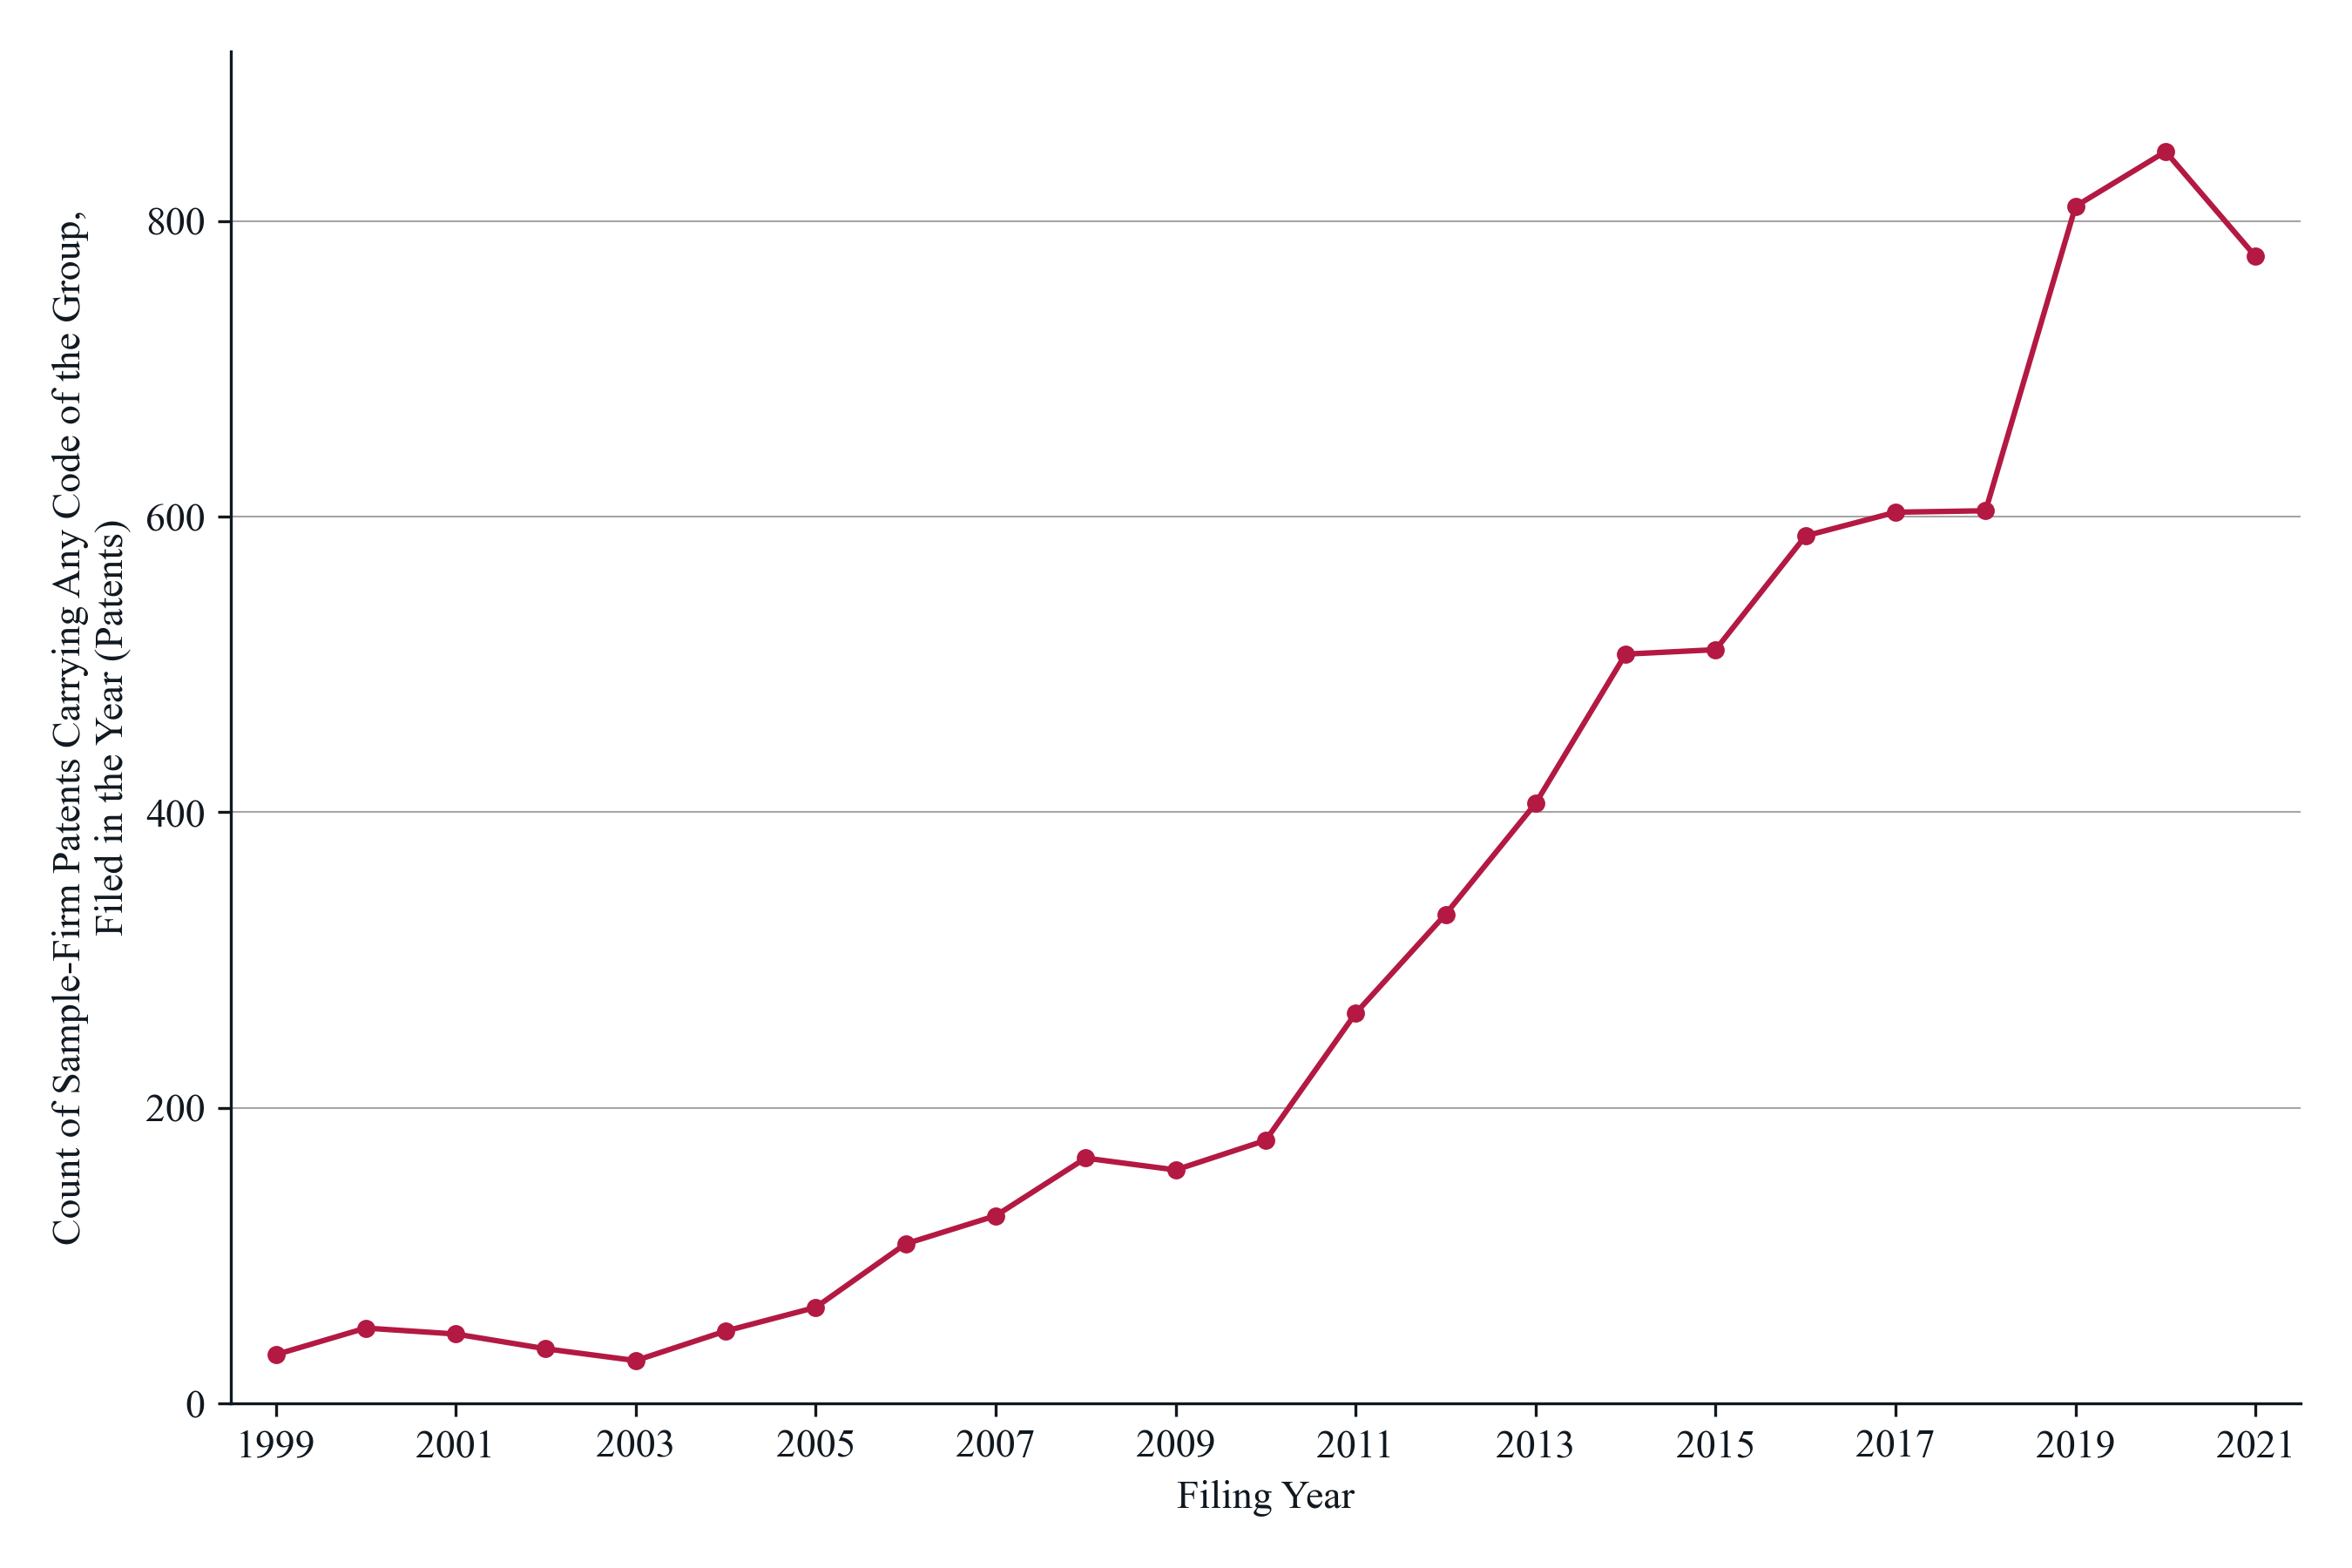

*Notes*: The line is the number of sample-firm KPSS patents filed in each year, 1999 to 2021, that carry at least one of the 14 codes of group B, use of personal data: tracking, profiling, targeting, and monitoring of people; a patent counts once however many of the group's codes it carries. 7,293 patents in all, from 33 in 1999 to a peak of 847 in 2020 and 776 in 2021. The group's codes, with their totals: H04W 4/029 2,577; G06Q 30/0269 1,430; G06Q 30/0255 1,011; G06Q 30/0261 959; G06Q 50/265 469; G06Q 10/063114 467; G06F 11/3438 457; H04L 67/535 354; G06Q 30/0271 311; G06Q 20/363 294; H04L 67/1396 3; G06Q 30/02011 0; G06Q 30/02023 0; G06Q 30/06311 0. A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [7]:
figure_number = 3
letter = "B"
figure_name = f"fig_{figure_number}_group_{letter}_pooled_by_filing_year"
title = f"Sample-Firm Patents Carrying Any Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Count of Sample-Firm Patents Carrying Any Code of the Group,\nFiled in the Year (Patents)"
series = group_counts.loc[letter]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.12)
axis.plot(years, series.to_numpy(), color=RED, linewidth=1.5, marker="o", markersize=4, zorder=3)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(series.max(), 1) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
y_title_box = axis.yaxis.label.get_window_extent(renderer)
assert y_title_box.y0 >= margin_pixels - 1 and y_title_box.y1 <= figure.bbox.height - margin_pixels + 1, f"Y-title runs from {y_title_box.y0 / figure.dpi:.2f} to {y_title_box.y1 / figure.dpi:.2f} inches"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

members = summary.loc[summary["group_letter"] == letter]
peak_year = int(series.idxmax())
notes = (f"The line is the number of sample-firm KPSS patents filed in each year, {PERIOD_WORDS}, that carry at least one of the {len(members)} codes of group {letter}, {GROUP_WORDS[letter]}; "
         f"a patent counts once however many of the group's codes it carries. {int(group_totals.get(letter, 0)):,} patents in all, from {int(series.iloc[0]):,} in {PERIOD_START} to a peak of "
         f"{int(series.max()):,} in {peak_year} and {int(series.iloc[-1]):,} in {PERIOD_END}. The group's codes, with their totals: "
         + "; ".join(f"{d} {n:,}" for d, n in zip(members["cpc_display"], members["n_patents"])) +
         ". A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted "
         "patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 8. Figure 4: group B by code, one panel per code of the group

All codes of group B on one canvas, ordered by total, each panel a RED line with markers over the filing years with its own vertical scale, a solid BLACK zero line, and a title with the code, its total, and its first grant year. The grid and font size follow the number of codes. The panel block is positioned after drawing so that it clears the margins and the shared axis titles. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 4. Sample-Firm Patents Carrying Each Code of Group B, Use of Personal Data, by Filing Year, 14 Codes, 1999 to 2021**

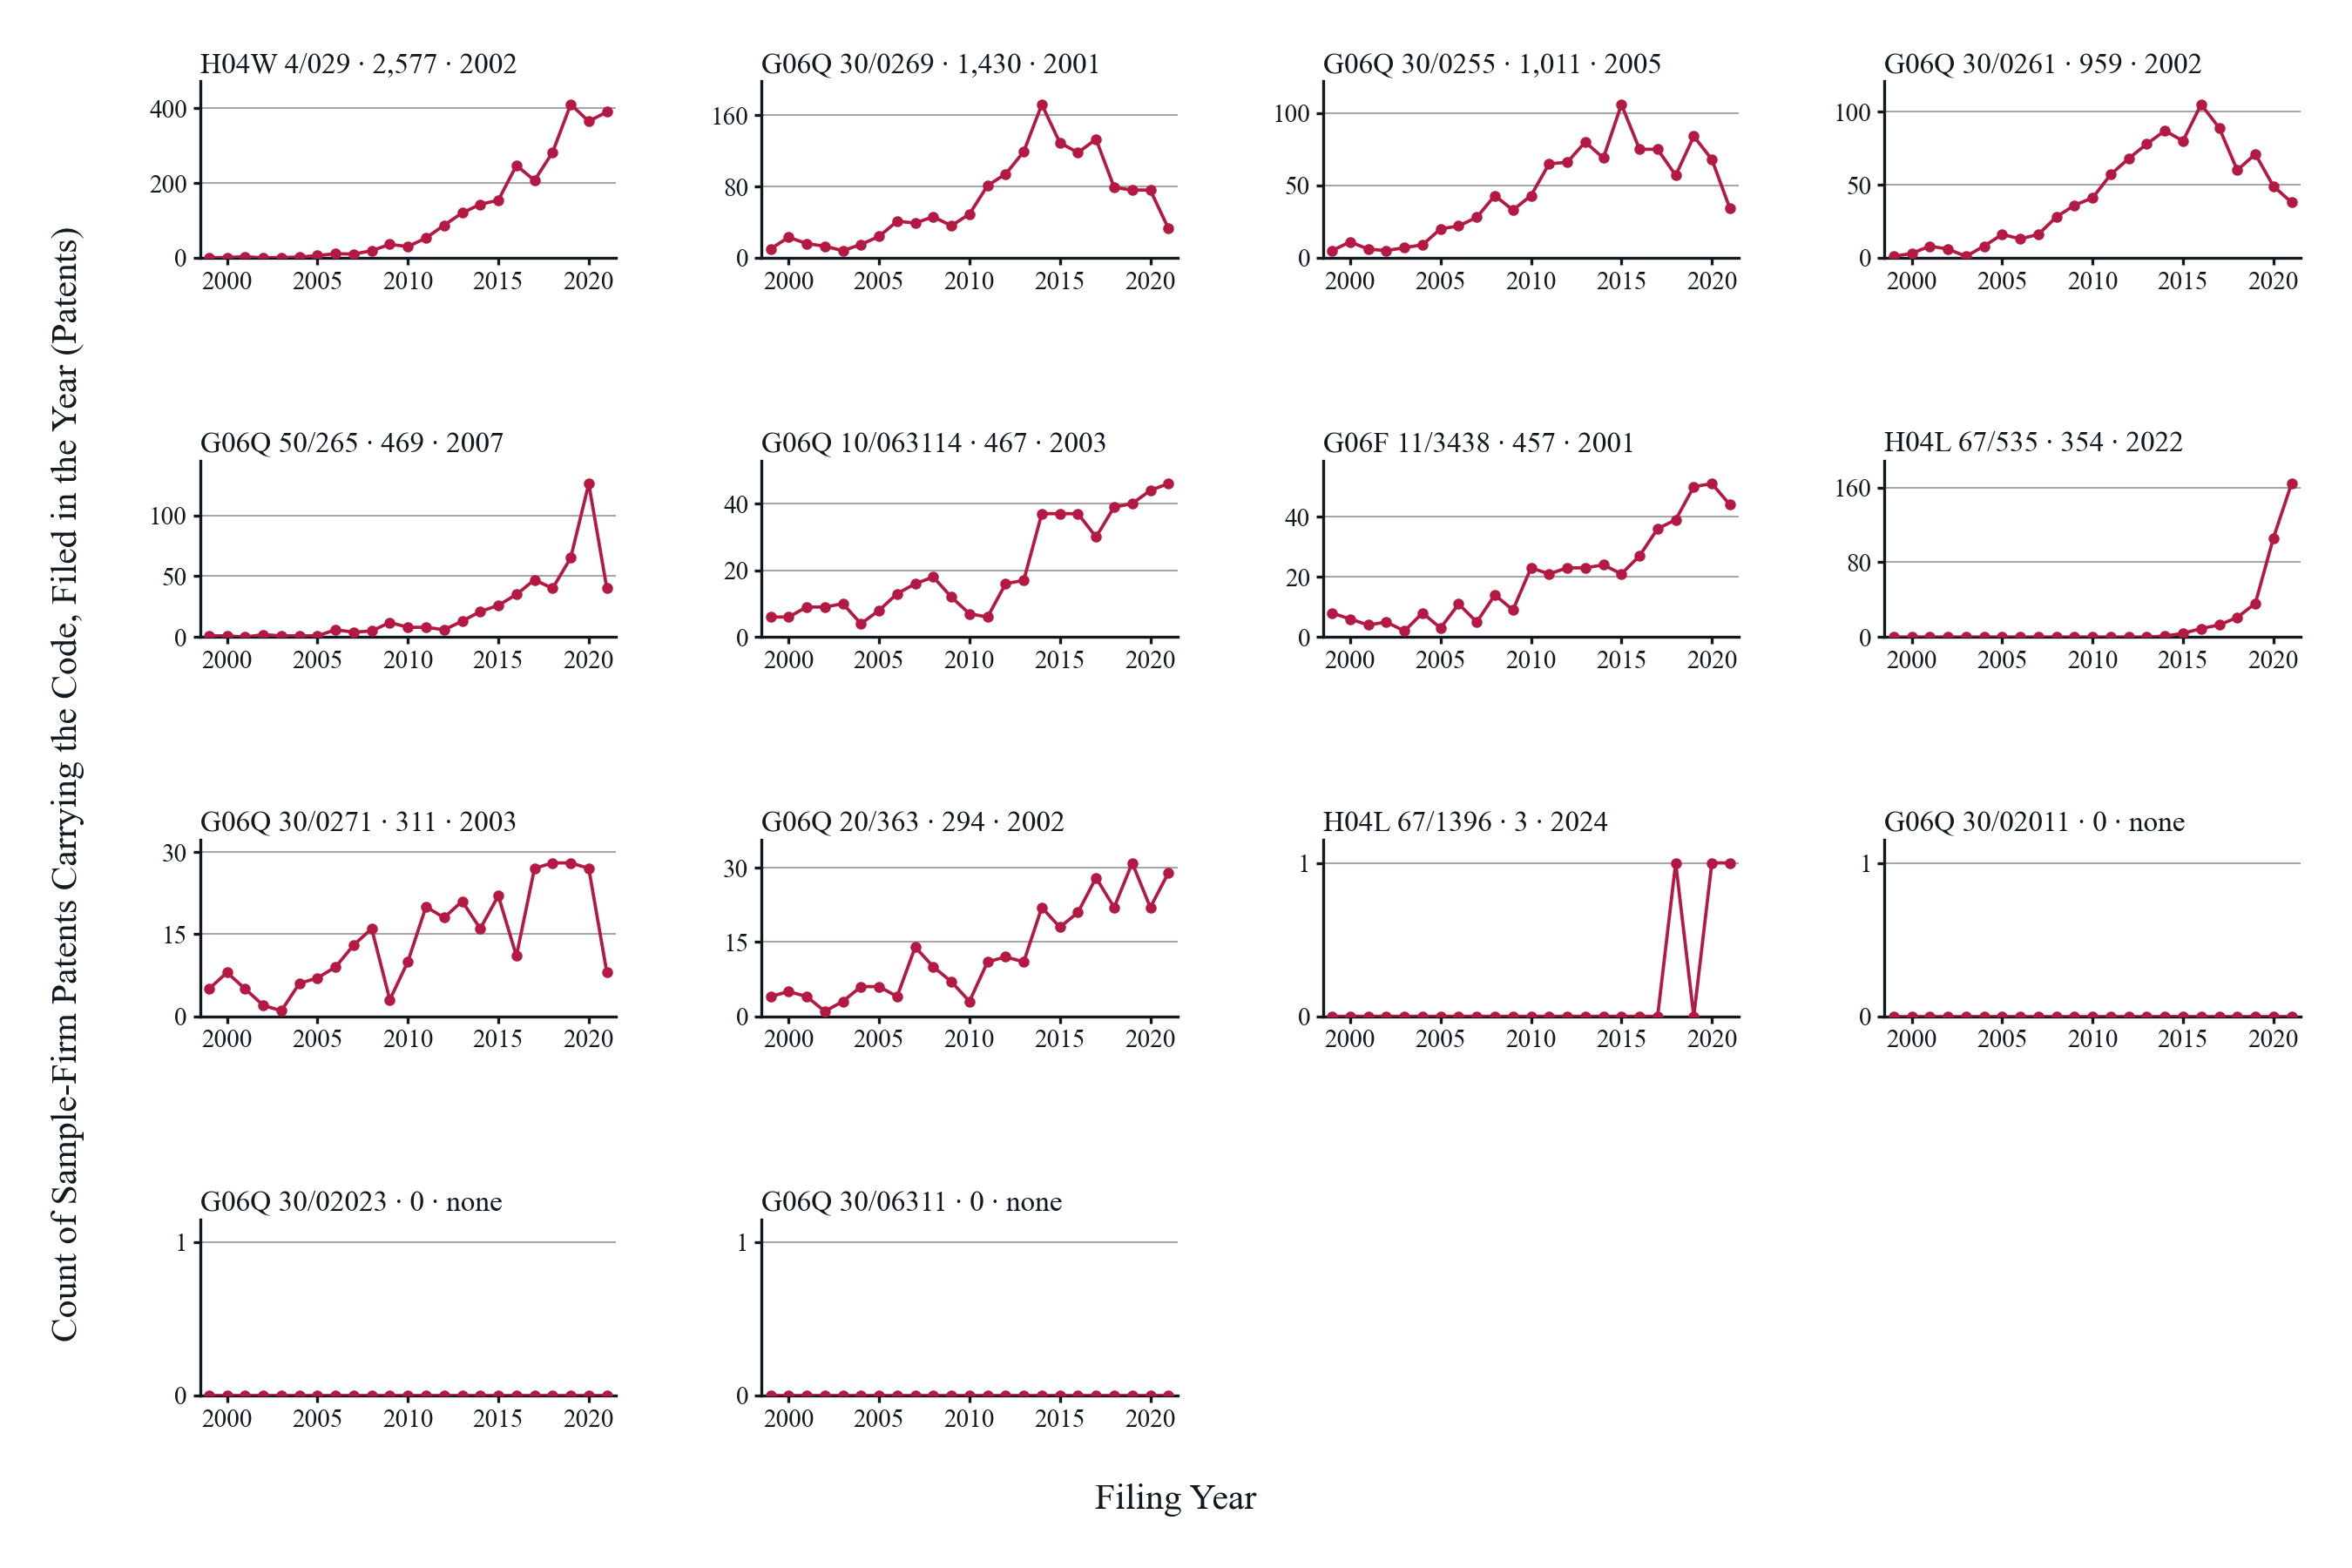

*Notes*: Each panel is one of the 14 codes of group B, use of personal data: tracking, profiling, targeting, and monitoring of people, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, by filing year, 1999 to 2021; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. Codes in this group whose first grant is 2015 or later: H04L 67/535 (2022), H04L 67/1396 (2024). Codes with no sample-firm patent in the period: G06Q 30/02011, G06Q 30/02023, G06Q 30/06311. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [8]:
figure_number = 4
letter = "B"
figure_name = f"fig_{figure_number}_group_{letter}_codes_by_filing_year"
members = summary.loc[summary["group_letter"] == letter]
n = len(members)
columns = 2 if n <= 2 else (4 if n <= 24 else 6)
rows = int(np.ceil(n / columns))
font_size = 7 if columns <= 4 else 6
title = f"Sample-Firm Patents Carrying Each Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {n} Codes, {PERIOD_WORDS}"
figure, axes = plt.subplots(rows, columns, figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), squeeze=False)
figure.subplots_adjust(left=0.085, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.95, bottom=0.11, hspace=0.75 + 0.1 * rows, wspace=0.35)
x_ticks = [2000, 2010, 2020] if columns == 6 else [2000, 2005, 2010, 2015, 2020]
for axis, code in zip(axes.flat, members.index):
    series = code_counts.loc[code]
    axis.plot(years, series.to_numpy(), color=RED, linewidth=0.9, marker="o", markersize=1.5 if columns == 6 else 2, zorder=3)
    axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
    axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
    axis.set_ylim(0, max(series.max(), 1) * 1.15)
    axis.set_xticks(x_ticks)
    axis.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3, integer=True))
    axis.yaxis.set_major_formatter(THOUSANDS)
    axis.tick_params(labelsize=font_size, length=2, pad=1.5)
    first_grant = int(members.loc[code, "first_grant_year"]) if pd.notna(members.loc[code, "first_grant_year"]) else "none"
    axis.set_title(f"{members.loc[code, 'cpc_display']} · {members.loc[code, 'n_patents']:,} · {first_grant}", fontsize=font_size + 1, pad=2.5, loc="left")
    axis.spines[["top", "right"]].set_visible(False)
for axis in list(axes.flat)[n:]:
    axis.set_visible(False)
x_label = figure.supxlabel("Filing Year", fontsize=10, y=MARGIN_INCHES / FIGURE_HEIGHT, va="bottom")
y_label = figure.supylabel("Count of Sample-Firm Patents Carrying the Code, Filed in the Year (Patents)", fontsize=10, x=MARGIN_INCHES / FIGURE_WIDTH, ha="left")
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
# Margins: the panel block is moved so that it clears the top margin, the X-title below, and the Y-title to the left, then checked.
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
gap = 0.3 * margin_pixels
top_overflow = max(b.y1 for b in boxes) - (figure.bbox.height - margin_pixels)
bottom_deficit = x_label.get_window_extent(renderer).y1 + gap - min(b.y0 for b in boxes)
left_deficit = y_label.get_window_extent(renderer).x1 + gap - min(b.x0 for b in boxes)
right_overflow = max(b.x1 for b in boxes) - (figure.bbox.width - margin_pixels)
figure.subplots_adjust(top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height, bottom=figure.subplotpars.bottom + max(bottom_deficit, 0) / figure.bbox.height,
                       left=figure.subplotpars.left + max(left_deficit, 0) / figure.bbox.width, right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width)
figure.canvas.draw()
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
assert min(b.x0 for b in boxes) >= y_label.get_window_extent(renderer).x1 - 1 and max(b.x1 for b in boxes) <= figure.bbox.width - margin_pixels + 1, "panels cross the side margins"
assert max(b.y1 for b in boxes) <= figure.bbox.height - margin_pixels + 1 and min(b.y0 for b in boxes) >= x_label.get_window_extent(renderer).y1 - 1, "panels cross the top margin or the X-title"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

late = [f"{members.loc[c, 'cpc_display']} ({int(members.loc[c, 'first_grant_year'])})" for c in members.index if pd.notna(members.loc[c, "first_grant_year"]) and members.loc[c, "first_grant_year"] >= 2015]
empty = [members.loc[c, "cpc_display"] for c in members.index if members.loc[c, "n_patents"] == 0]
notes = (f"Each panel is one of the {n} codes of group {letter}, {GROUP_WORDS[letter]}, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, "
         f"by filing year, {PERIOD_WORDS}; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a "
         "patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows "
         "nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. "
         f"Codes in this group whose first grant is 2015 or later: {', '.join(late) if late else 'none'}. Codes with no sample-firm patent in the period: {', '.join(empty) if empty else 'none'}. "
         "Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 "
         "firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 9. Figure 5: group C pooled, patents carrying any code of the group by filing year

One RED line with markers, the distinct sample-firm patents filed in each year that carry at least one code of group C; a solid BLACK zero line; no legend. The Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge, measured after drawing. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 5. Sample-Firm Patents Carrying Any Code of Group C, Interception by Authorities, by Filing Year, 1999 to 2021**

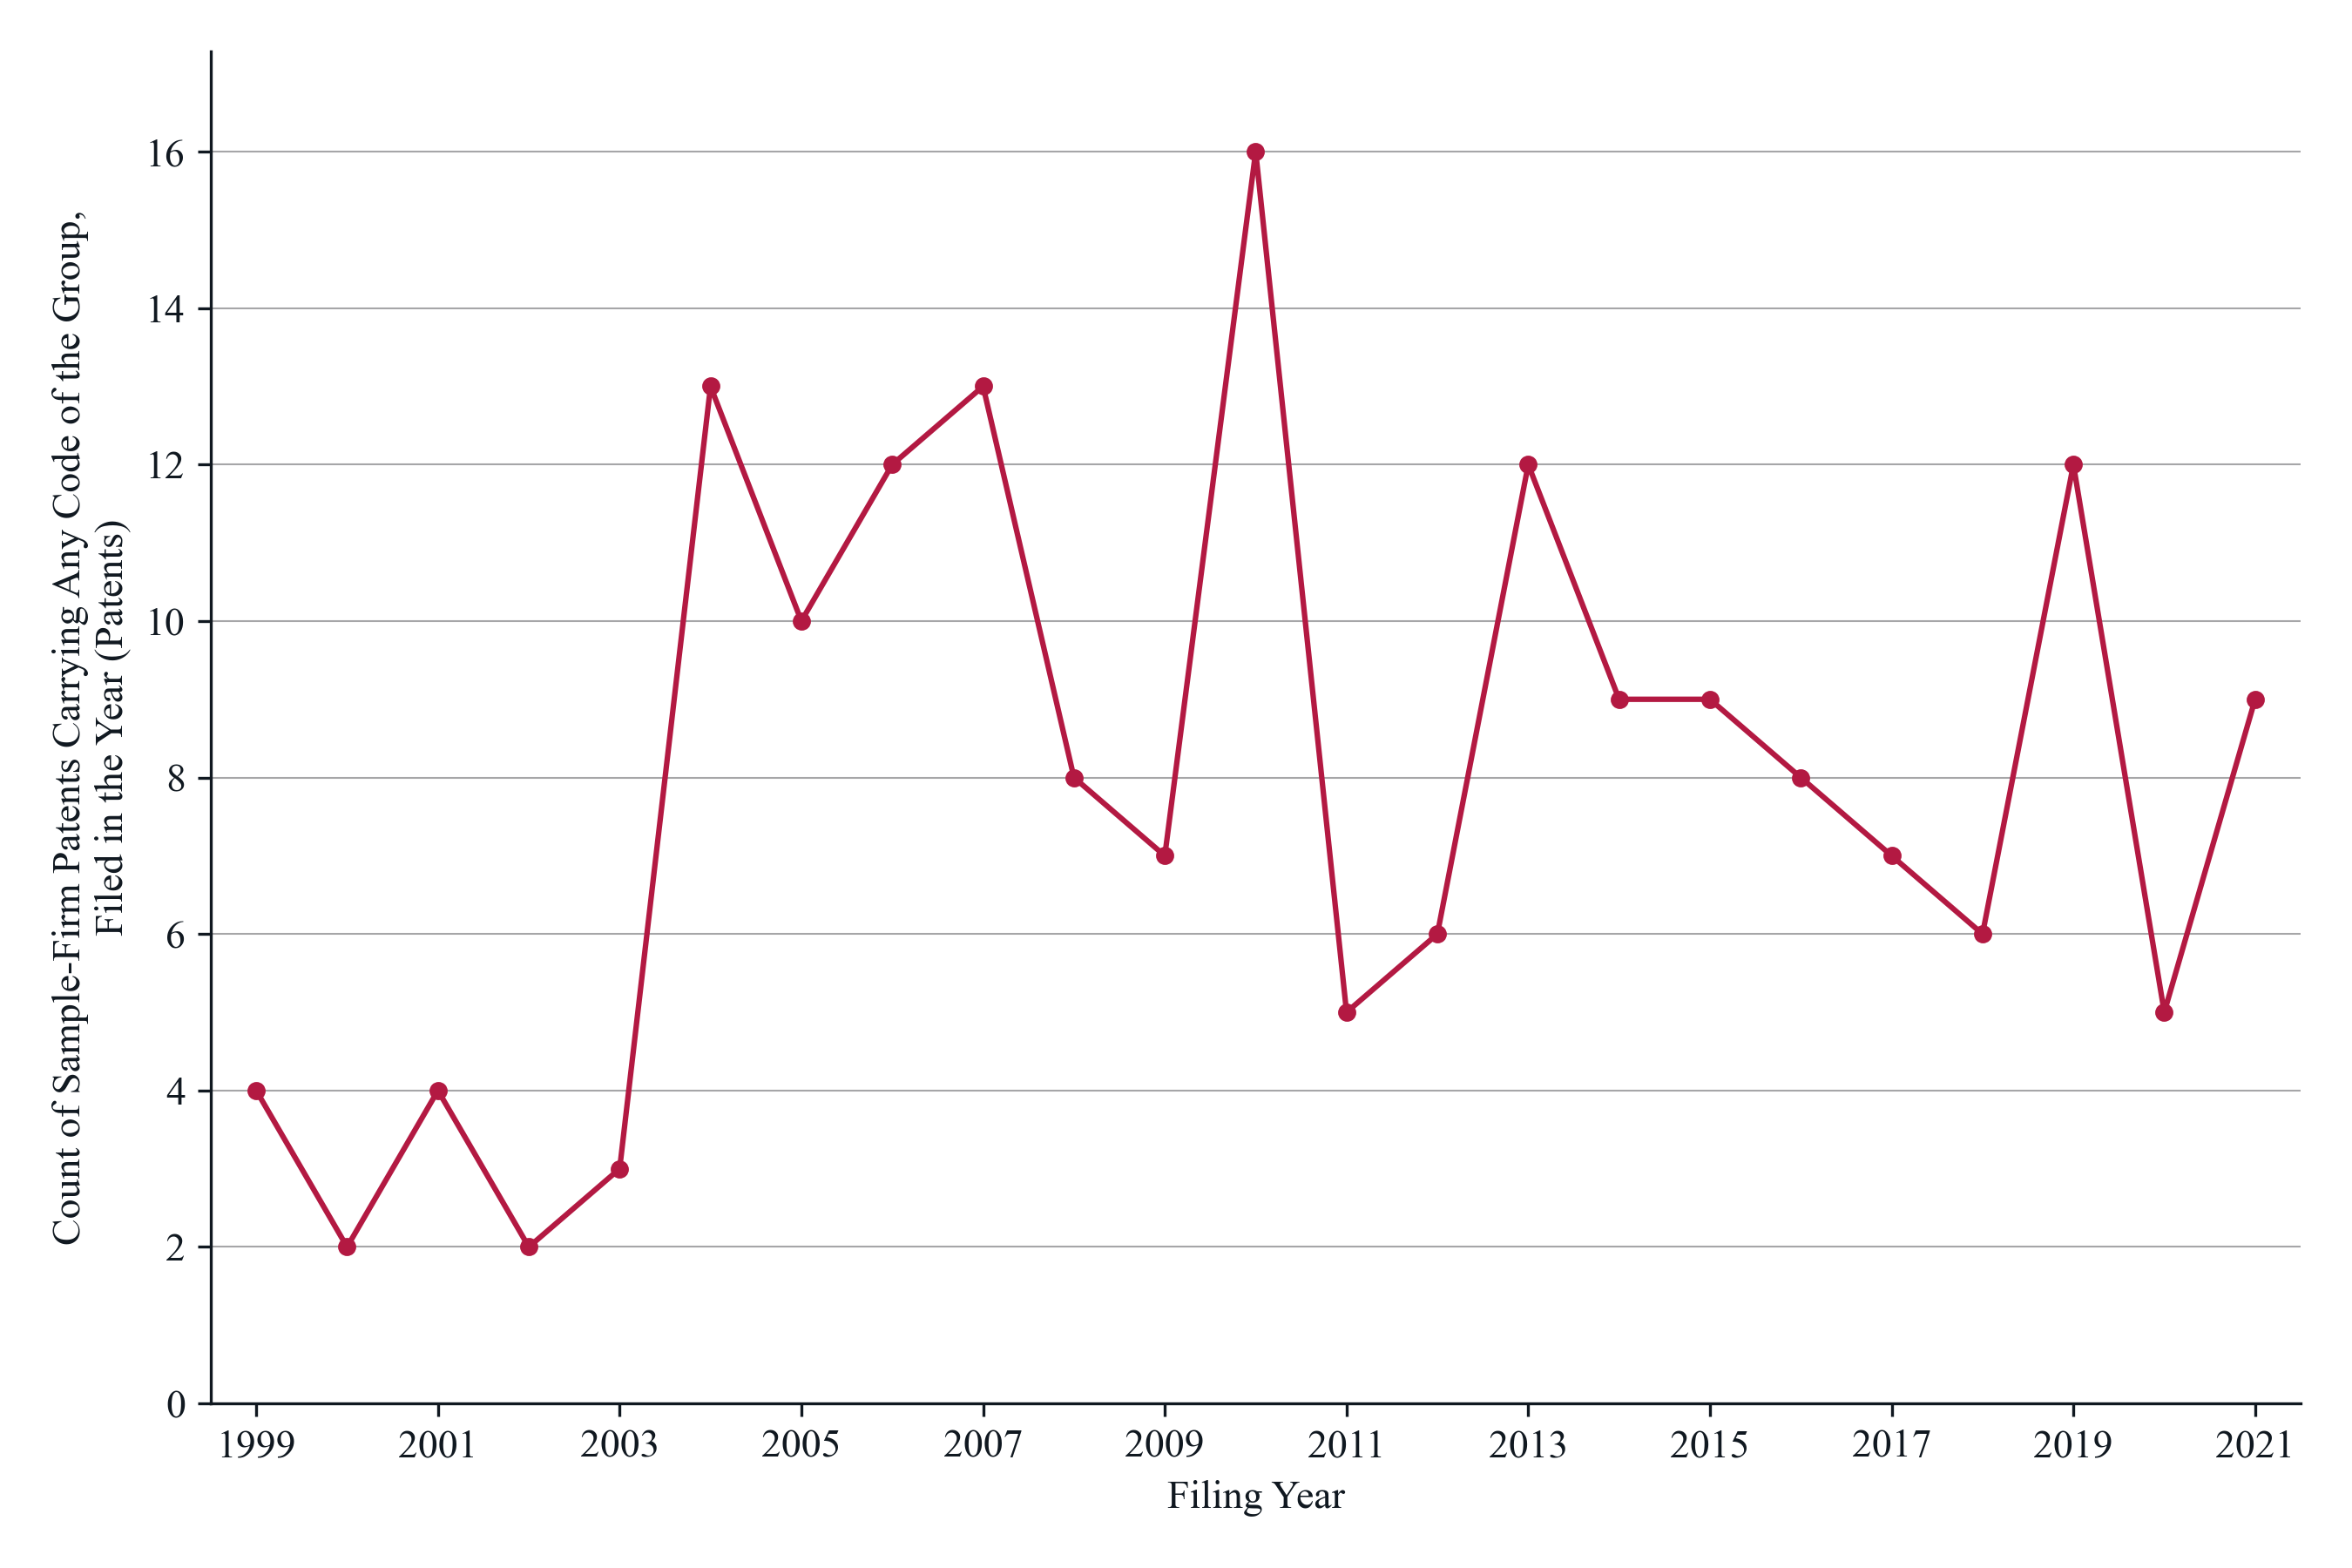

*Notes*: The line is the number of sample-firm KPSS patents filed in each year, 1999 to 2021, that carry at least one of the 2 codes of group C, interception of communications by authorities; a patent counts once however many of the group's codes it carries. 182 patents in all, from 4 in 1999 to a peak of 16 in 2010 and 9 in 2021. The group's codes, with their totals: H04L 63/30 173; H04W 12/80 12. A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [9]:
figure_number = 5
letter = "C"
figure_name = f"fig_{figure_number}_group_{letter}_pooled_by_filing_year"
title = f"Sample-Firm Patents Carrying Any Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Count of Sample-Firm Patents Carrying Any Code of the Group,\nFiled in the Year (Patents)"
series = group_counts.loc[letter]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.12)
axis.plot(years, series.to_numpy(), color=RED, linewidth=1.5, marker="o", markersize=4, zorder=3)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(series.max(), 1) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
y_title_box = axis.yaxis.label.get_window_extent(renderer)
assert y_title_box.y0 >= margin_pixels - 1 and y_title_box.y1 <= figure.bbox.height - margin_pixels + 1, f"Y-title runs from {y_title_box.y0 / figure.dpi:.2f} to {y_title_box.y1 / figure.dpi:.2f} inches"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

members = summary.loc[summary["group_letter"] == letter]
peak_year = int(series.idxmax())
notes = (f"The line is the number of sample-firm KPSS patents filed in each year, {PERIOD_WORDS}, that carry at least one of the {len(members)} codes of group {letter}, {GROUP_WORDS[letter]}; "
         f"a patent counts once however many of the group's codes it carries. {int(group_totals.get(letter, 0)):,} patents in all, from {int(series.iloc[0]):,} in {PERIOD_START} to a peak of "
         f"{int(series.max()):,} in {peak_year} and {int(series.iloc[-1]):,} in {PERIOD_END}. The group's codes, with their totals: "
         + "; ".join(f"{d} {n:,}" for d, n in zip(members["cpc_display"], members["n_patents"])) +
         ". A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted "
         "patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 10. Figure 6: group C by code, one panel per code of the group

All codes of group C on one canvas, ordered by total, each panel a RED line with markers over the filing years with its own vertical scale, a solid BLACK zero line, and a title with the code, its total, and its first grant year. The grid and font size follow the number of codes. The panel block is positioned after drawing so that it clears the margins and the shared axis titles. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 6. Sample-Firm Patents Carrying Each Code of Group C, Interception by Authorities, by Filing Year, 2 Codes, 1999 to 2021**

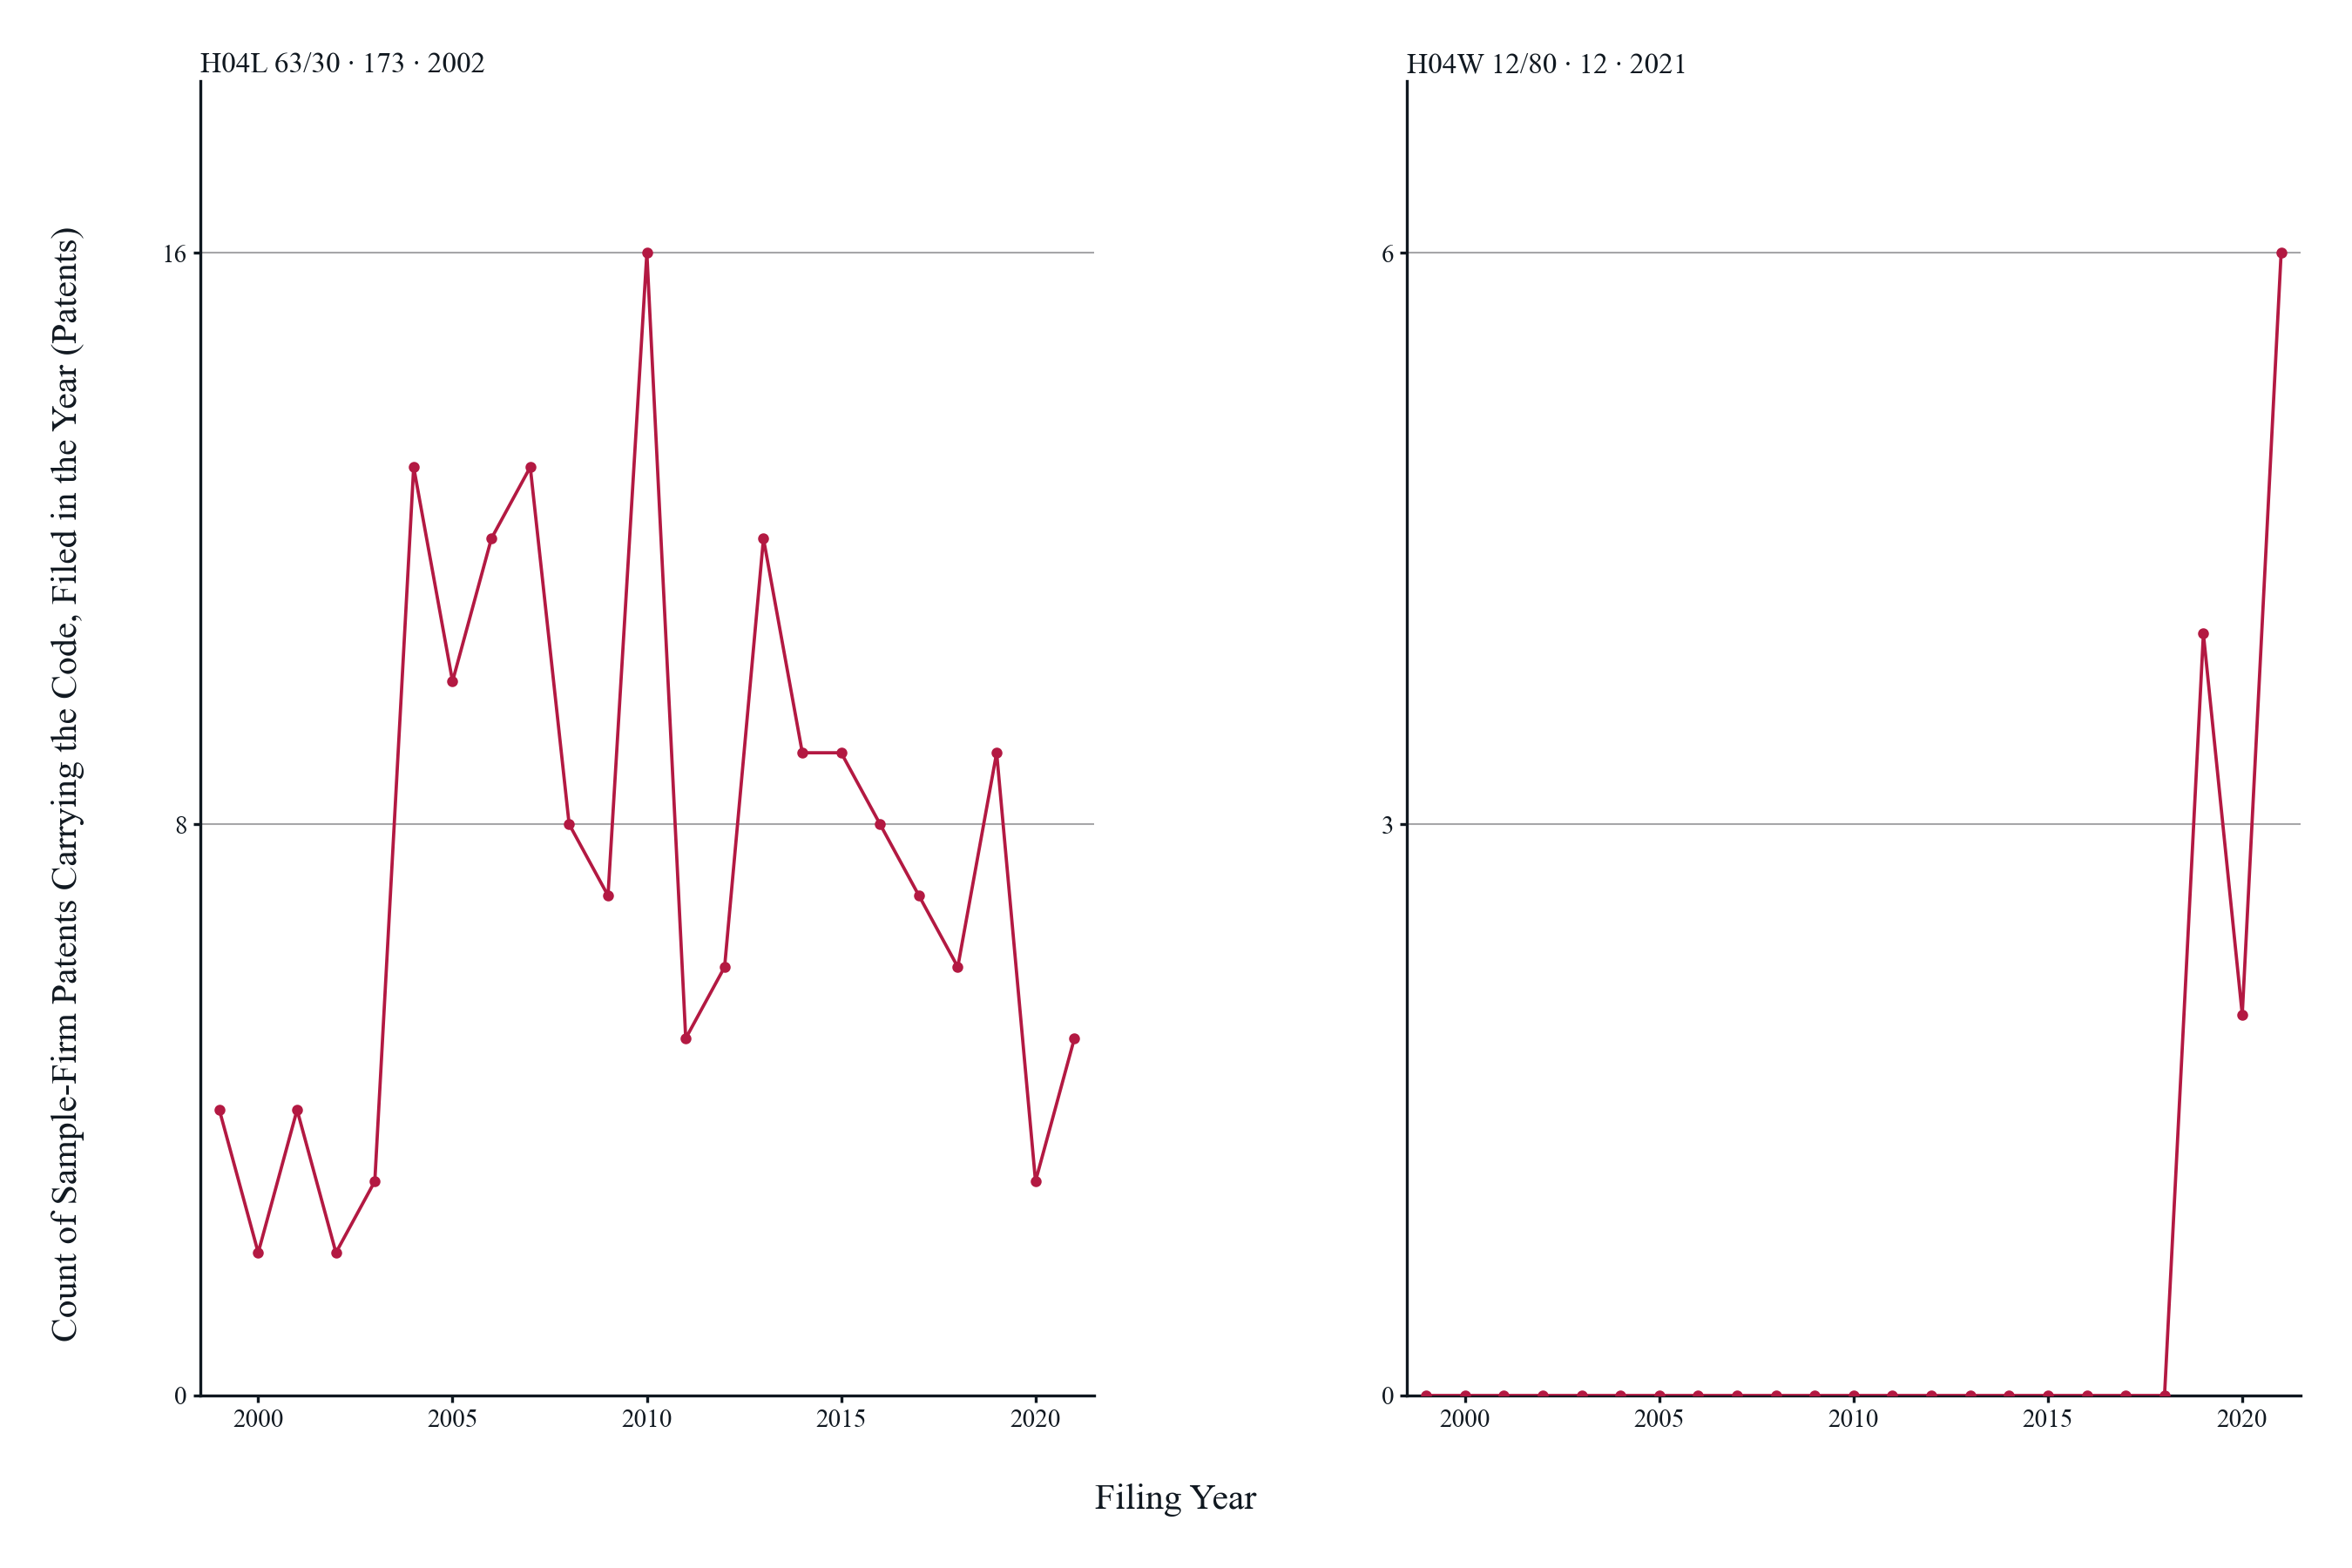

*Notes*: Each panel is one of the 2 codes of group C, interception of communications by authorities, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, by filing year, 1999 to 2021; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. Codes in this group whose first grant is 2015 or later: H04W 12/80 (2021). Codes with no sample-firm patent in the period: none. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [10]:
figure_number = 6
letter = "C"
figure_name = f"fig_{figure_number}_group_{letter}_codes_by_filing_year"
members = summary.loc[summary["group_letter"] == letter]
n = len(members)
columns = 2 if n <= 2 else (4 if n <= 24 else 6)
rows = int(np.ceil(n / columns))
font_size = 7 if columns <= 4 else 6
title = f"Sample-Firm Patents Carrying Each Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {n} Codes, {PERIOD_WORDS}"
figure, axes = plt.subplots(rows, columns, figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), squeeze=False)
figure.subplots_adjust(left=0.085, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.95, bottom=0.11, hspace=0.75 + 0.1 * rows, wspace=0.35)
x_ticks = [2000, 2010, 2020] if columns == 6 else [2000, 2005, 2010, 2015, 2020]
for axis, code in zip(axes.flat, members.index):
    series = code_counts.loc[code]
    axis.plot(years, series.to_numpy(), color=RED, linewidth=0.9, marker="o", markersize=1.5 if columns == 6 else 2, zorder=3)
    axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
    axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
    axis.set_ylim(0, max(series.max(), 1) * 1.15)
    axis.set_xticks(x_ticks)
    axis.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3, integer=True))
    axis.yaxis.set_major_formatter(THOUSANDS)
    axis.tick_params(labelsize=font_size, length=2, pad=1.5)
    first_grant = int(members.loc[code, "first_grant_year"]) if pd.notna(members.loc[code, "first_grant_year"]) else "none"
    axis.set_title(f"{members.loc[code, 'cpc_display']} · {members.loc[code, 'n_patents']:,} · {first_grant}", fontsize=font_size + 1, pad=2.5, loc="left")
    axis.spines[["top", "right"]].set_visible(False)
for axis in list(axes.flat)[n:]:
    axis.set_visible(False)
x_label = figure.supxlabel("Filing Year", fontsize=10, y=MARGIN_INCHES / FIGURE_HEIGHT, va="bottom")
y_label = figure.supylabel("Count of Sample-Firm Patents Carrying the Code, Filed in the Year (Patents)", fontsize=10, x=MARGIN_INCHES / FIGURE_WIDTH, ha="left")
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
# Margins: the panel block is moved so that it clears the top margin, the X-title below, and the Y-title to the left, then checked.
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
gap = 0.3 * margin_pixels
top_overflow = max(b.y1 for b in boxes) - (figure.bbox.height - margin_pixels)
bottom_deficit = x_label.get_window_extent(renderer).y1 + gap - min(b.y0 for b in boxes)
left_deficit = y_label.get_window_extent(renderer).x1 + gap - min(b.x0 for b in boxes)
right_overflow = max(b.x1 for b in boxes) - (figure.bbox.width - margin_pixels)
figure.subplots_adjust(top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height, bottom=figure.subplotpars.bottom + max(bottom_deficit, 0) / figure.bbox.height,
                       left=figure.subplotpars.left + max(left_deficit, 0) / figure.bbox.width, right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width)
figure.canvas.draw()
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
assert min(b.x0 for b in boxes) >= y_label.get_window_extent(renderer).x1 - 1 and max(b.x1 for b in boxes) <= figure.bbox.width - margin_pixels + 1, "panels cross the side margins"
assert max(b.y1 for b in boxes) <= figure.bbox.height - margin_pixels + 1 and min(b.y0 for b in boxes) >= x_label.get_window_extent(renderer).y1 - 1, "panels cross the top margin or the X-title"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

late = [f"{members.loc[c, 'cpc_display']} ({int(members.loc[c, 'first_grant_year'])})" for c in members.index if pd.notna(members.loc[c, "first_grant_year"]) and members.loc[c, "first_grant_year"] >= 2015]
empty = [members.loc[c, "cpc_display"] for c in members.index if members.loc[c, "n_patents"] == 0]
notes = (f"Each panel is one of the {n} codes of group {letter}, {GROUP_WORDS[letter]}, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, "
         f"by filing year, {PERIOD_WORDS}; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a "
         "patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows "
         "nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. "
         f"Codes in this group whose first grant is 2015 or later: {', '.join(late) if late else 'none'}. Codes with no sample-firm patent in the period: {', '.join(empty) if empty else 'none'}. "
         "Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 "
         "firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 11. Figure 7: group D pooled, patents carrying any code of the group by filing year

One RED line with markers, the distinct sample-firm patents filed in each year that carry at least one code of group D; a solid BLACK zero line; no legend. The Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge, measured after drawing. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 7. Sample-Firm Patents Carrying Any Code of Group D, Security, by Filing Year, 1999 to 2021**

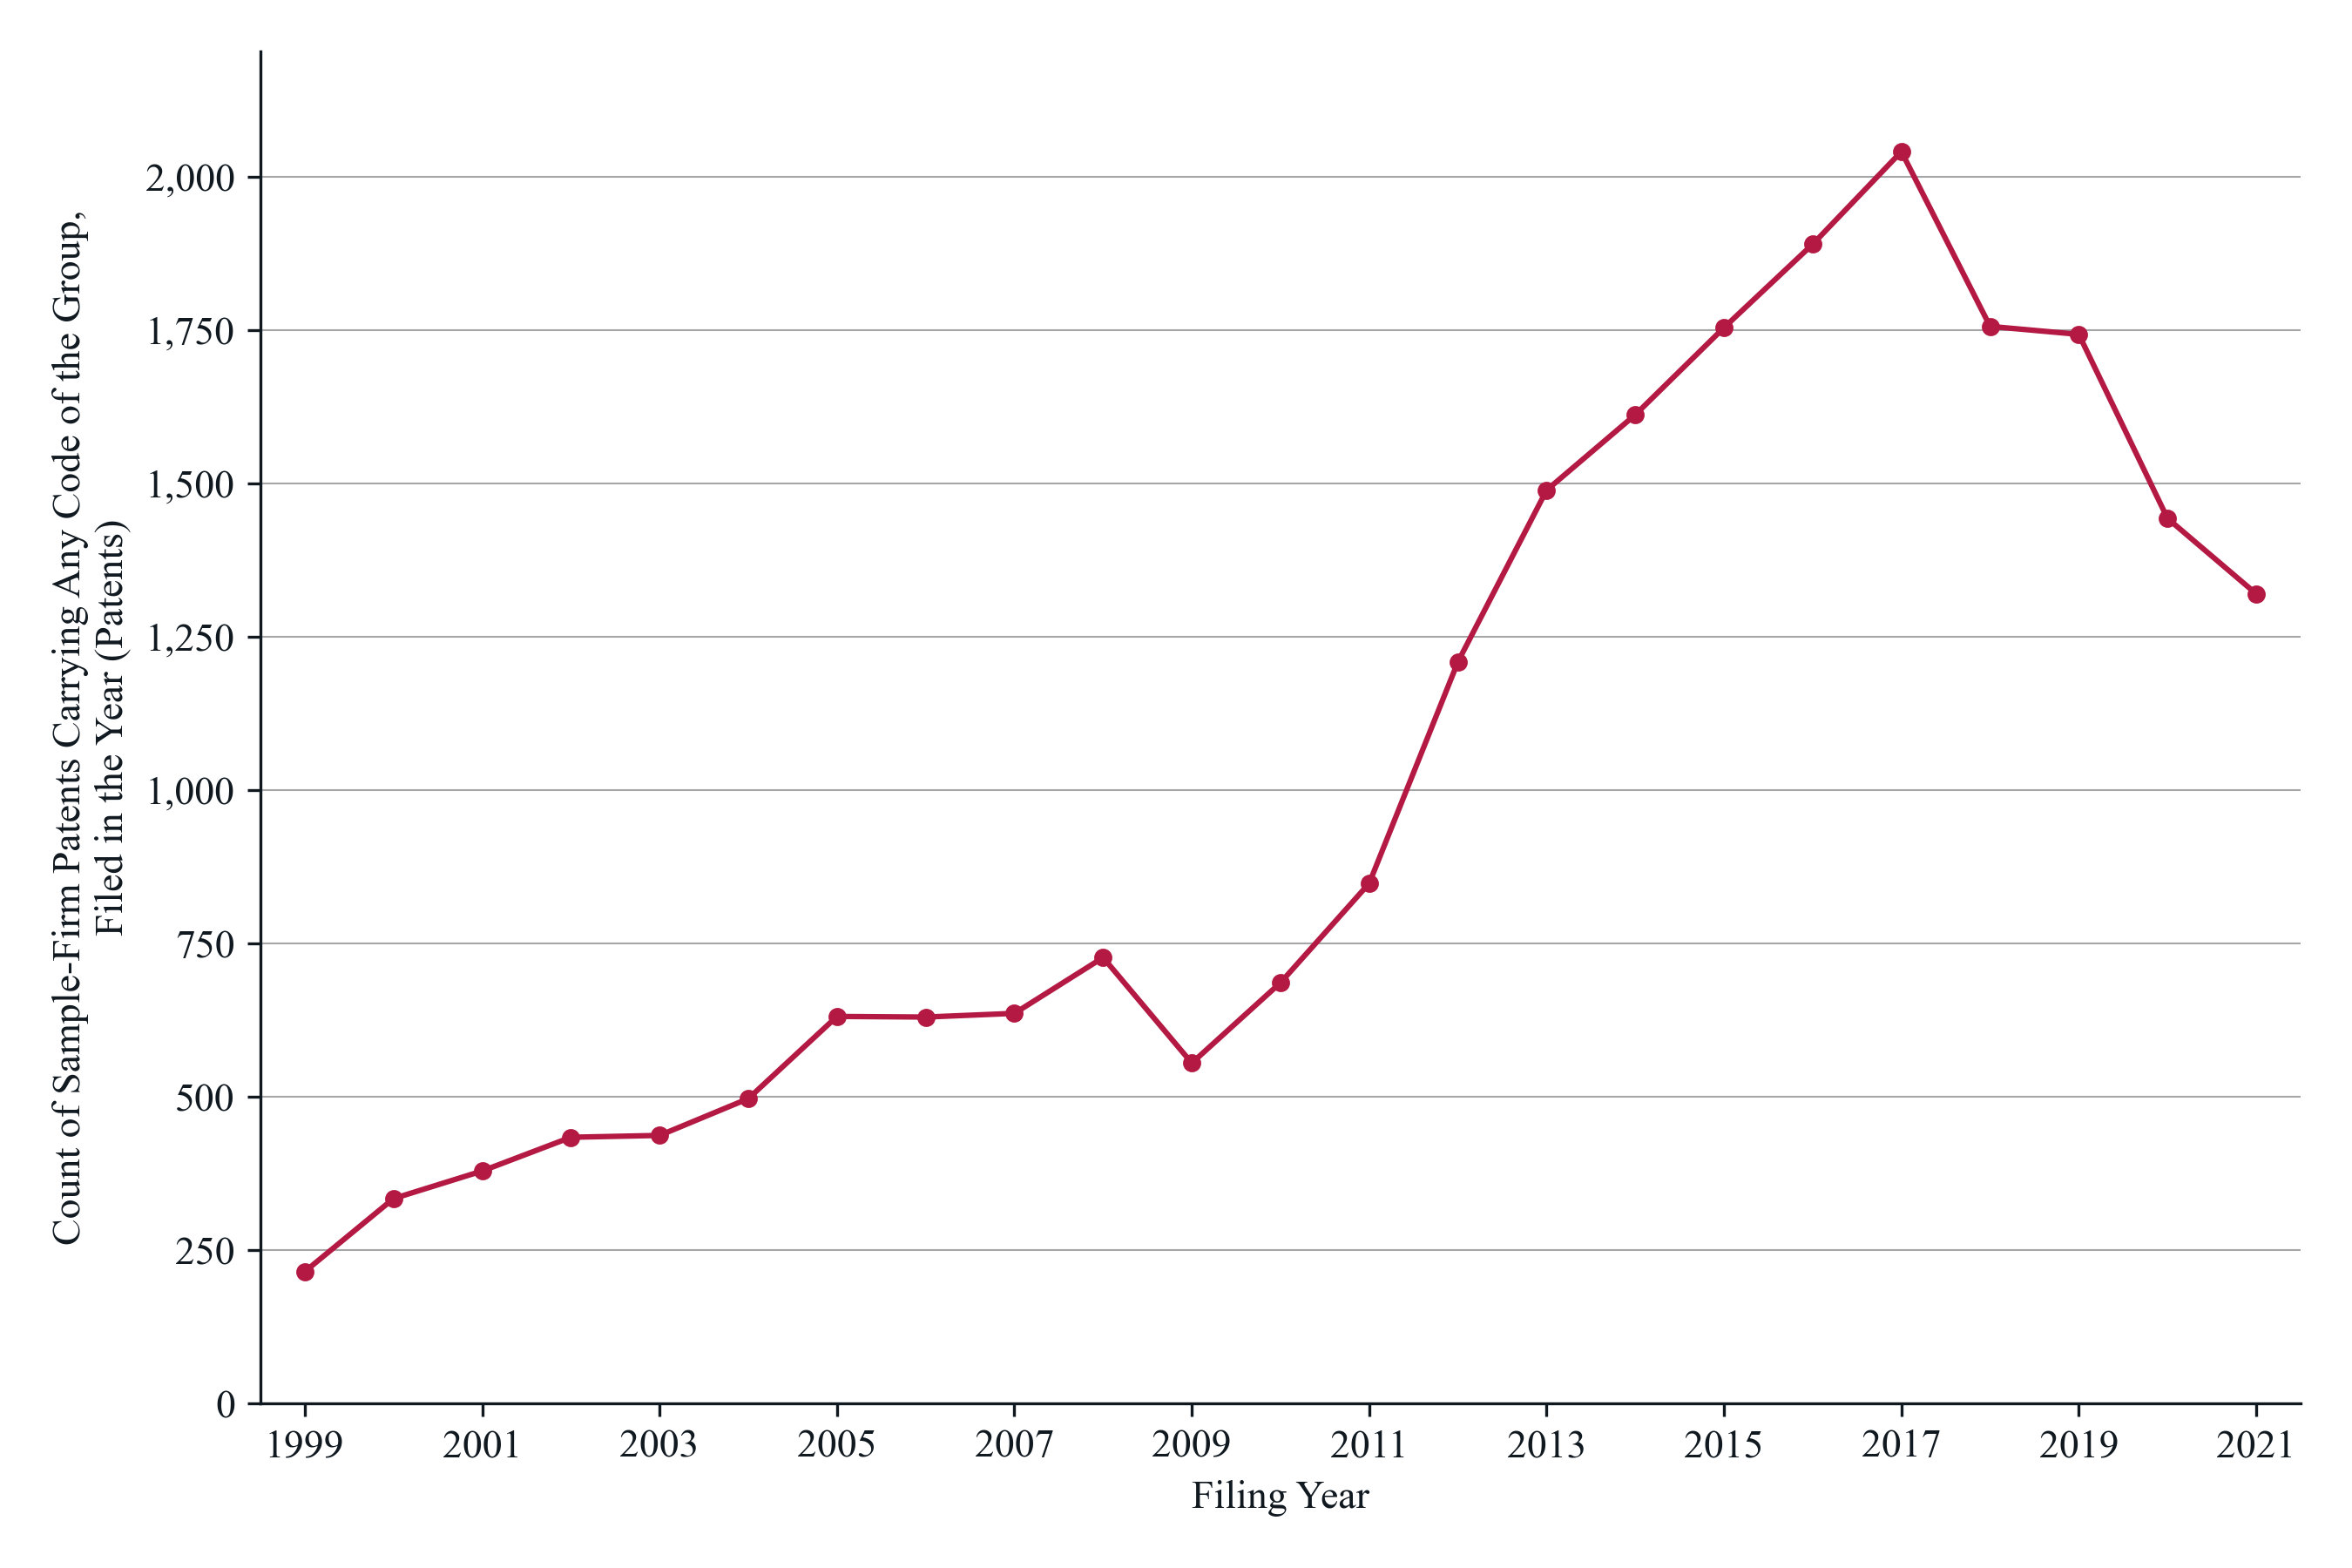

*Notes*: The line is the number of sample-firm KPSS patents filed in each year, 1999 to 2021, that carry at least one of the 34 codes of group D, security: encryption, access control, secure storage, and obfuscation; a patent counts once however many of the group's codes it carries. 23,266 patents in all, from 215 in 1999 to a peak of 2,041 in 2017 and 1,320 in 2021. The group's codes, with their totals: H04L 63/0428 4,394; H04L 63/10 4,135; G06F 21/6218 4,057; H04W 12/08 3,086; G06F 21/602 2,349; G06F 21/62 1,318; G06F 21/6227 1,244; G06F 21/6209 1,224; G06F 2221/2107 965; G06F 21/60 886; H04L 63/0442 875; G06F 21/78 775; H04L 63/0435 747; G06F 21/606 746; H04L 63/04 583; G06F 2221/2143 445; G06F 3/0623 377; G06F 21/84 316; H04L 63/0492 295; H04L 63/0485 281; H04L 63/045 247; H04L 63/0471 236; H04L 2209/16 225; G06F 21/556 189; H04L 63/0464 156; H04L 63/0457 154; H04W 12/03 142; H04W 12/033 135; H04L 63/1475 124; H04L 63/0478 118; H04W 12/037 100; H04W 12/084 55; H04W 12/082 34; H04L 12/22 12. A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [11]:
figure_number = 7
letter = "D"
figure_name = f"fig_{figure_number}_group_{letter}_pooled_by_filing_year"
title = f"Sample-Firm Patents Carrying Any Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Count of Sample-Firm Patents Carrying Any Code of the Group,\nFiled in the Year (Patents)"
series = group_counts.loc[letter]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.12)
axis.plot(years, series.to_numpy(), color=RED, linewidth=1.5, marker="o", markersize=4, zorder=3)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(series.max(), 1) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
y_title_box = axis.yaxis.label.get_window_extent(renderer)
assert y_title_box.y0 >= margin_pixels - 1 and y_title_box.y1 <= figure.bbox.height - margin_pixels + 1, f"Y-title runs from {y_title_box.y0 / figure.dpi:.2f} to {y_title_box.y1 / figure.dpi:.2f} inches"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

members = summary.loc[summary["group_letter"] == letter]
peak_year = int(series.idxmax())
notes = (f"The line is the number of sample-firm KPSS patents filed in each year, {PERIOD_WORDS}, that carry at least one of the {len(members)} codes of group {letter}, {GROUP_WORDS[letter]}; "
         f"a patent counts once however many of the group's codes it carries. {int(group_totals.get(letter, 0)):,} patents in all, from {int(series.iloc[0]):,} in {PERIOD_START} to a peak of "
         f"{int(series.max()):,} in {peak_year} and {int(series.iloc[-1]):,} in {PERIOD_END}. The group's codes, with their totals: "
         + "; ".join(f"{d} {n:,}" for d, n in zip(members["cpc_display"], members["n_patents"])) +
         ". A code's patents count toward every group whose codes they also carry, so the four pooled series overlap. Counts in the last years are lower in part because KPSS covers granted "
         "patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 12. Figure 8: group D by code, one panel per code of the group

All codes of group D on one canvas, ordered by total, each panel a RED line with markers over the filing years with its own vertical scale, a solid BLACK zero line, and a title with the code, its total, and its first grant year. The grid and font size follow the number of codes. The panel block is positioned after drawing so that it clears the margins and the shared axis titles. Exported as PNG, SVG, and PDF and shown with its title, Notes, and Source.


**Figure 8. Sample-Firm Patents Carrying Each Code of Group D, Security, by Filing Year, 34 Codes, 1999 to 2021**

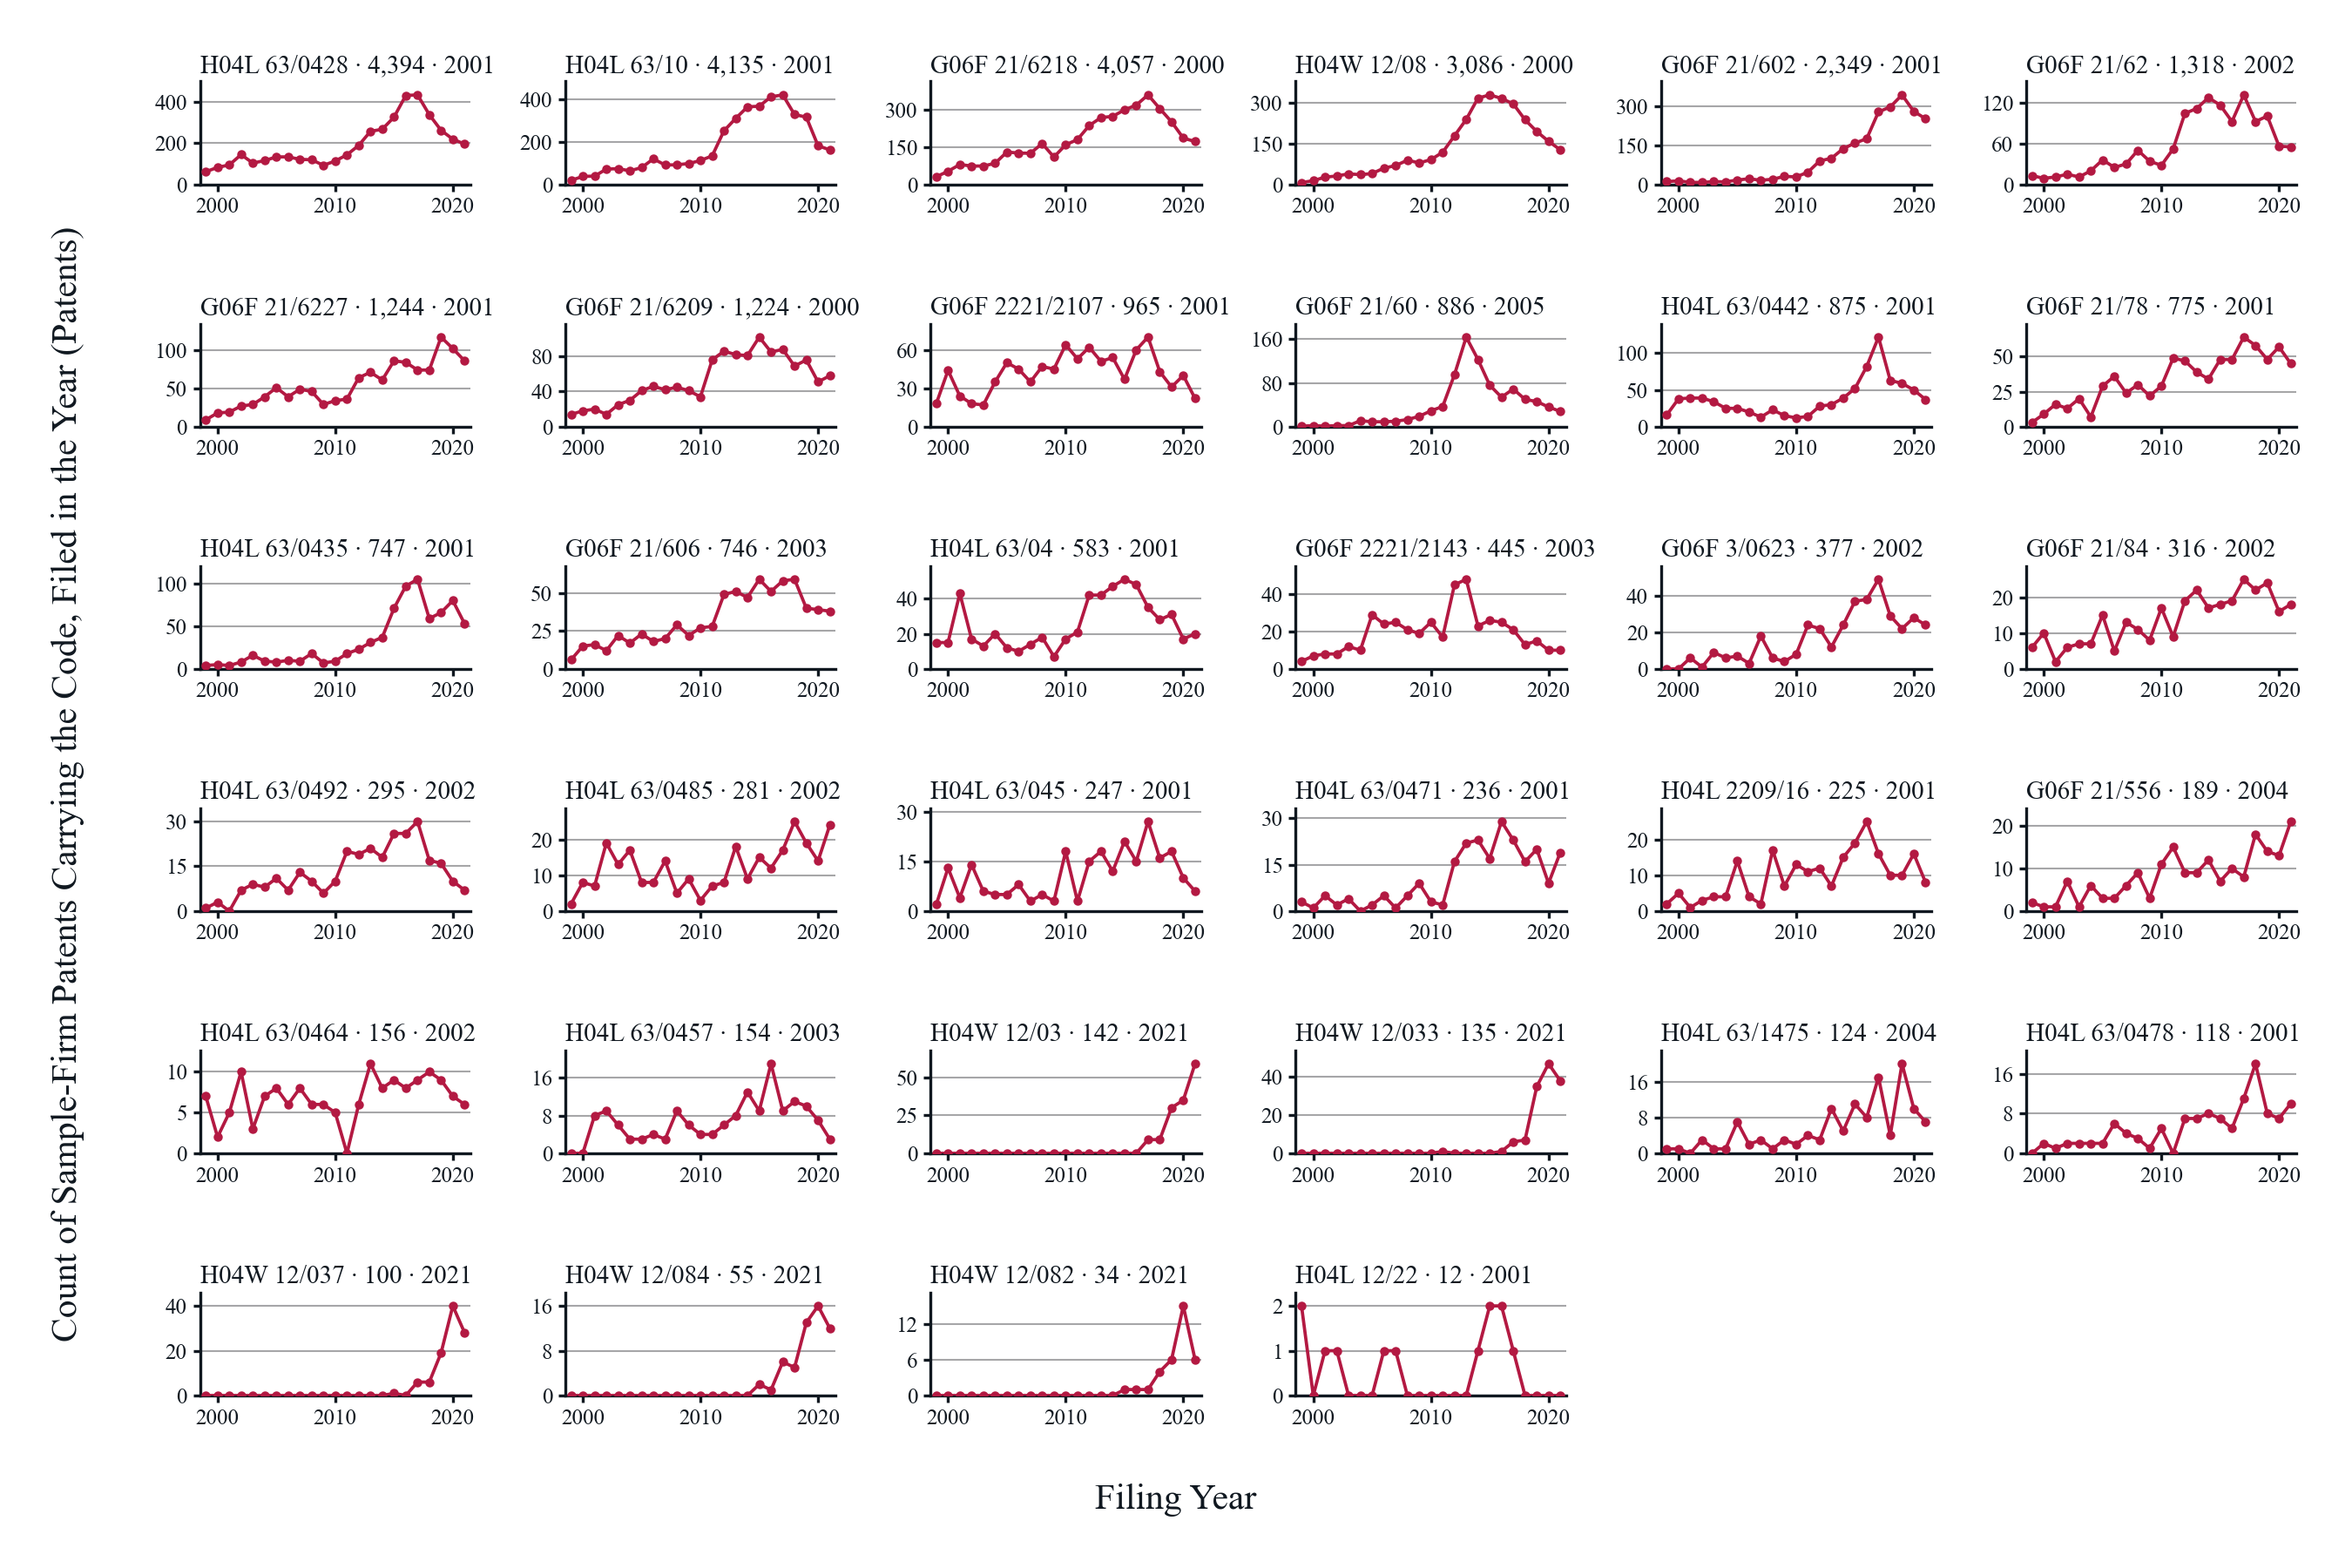

*Notes*: Each panel is one of the 34 codes of group D, security: encryption, access control, secure storage, and obfuscation, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, by filing year, 1999 to 2021; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. Codes in this group whose first grant is 2015 or later: H04W 12/03 (2021), H04W 12/033 (2021), H04W 12/037 (2021), H04W 12/084 (2021), H04W 12/082 (2021). Codes with no sample-firm patent in the period: none. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list and its grouping in privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv; sample firms from the 10-K sample of T3; authors' calculations.

In [12]:
figure_number = 8
letter = "D"
figure_name = f"fig_{figure_number}_group_{letter}_codes_by_filing_year"
members = summary.loc[summary["group_letter"] == letter]
n = len(members)
columns = 2 if n <= 2 else (4 if n <= 24 else 6)
rows = int(np.ceil(n / columns))
font_size = 7 if columns <= 4 else 6
title = f"Sample-Firm Patents Carrying Each Code of Group {letter}, {GROUP_TITLES[letter]}, by Filing Year, {n} Codes, {PERIOD_WORDS}"
figure, axes = plt.subplots(rows, columns, figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), squeeze=False)
figure.subplots_adjust(left=0.085, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.95, bottom=0.11, hspace=0.75 + 0.1 * rows, wspace=0.35)
x_ticks = [2000, 2010, 2020] if columns == 6 else [2000, 2005, 2010, 2015, 2020]
for axis, code in zip(axes.flat, members.index):
    series = code_counts.loc[code]
    axis.plot(years, series.to_numpy(), color=RED, linewidth=0.9, marker="o", markersize=1.5 if columns == 6 else 2, zorder=3)
    axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
    axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
    axis.set_ylim(0, max(series.max(), 1) * 1.15)
    axis.set_xticks(x_ticks)
    axis.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3, integer=True))
    axis.yaxis.set_major_formatter(THOUSANDS)
    axis.tick_params(labelsize=font_size, length=2, pad=1.5)
    first_grant = int(members.loc[code, "first_grant_year"]) if pd.notna(members.loc[code, "first_grant_year"]) else "none"
    axis.set_title(f"{members.loc[code, 'cpc_display']} · {members.loc[code, 'n_patents']:,} · {first_grant}", fontsize=font_size + 1, pad=2.5, loc="left")
    axis.spines[["top", "right"]].set_visible(False)
for axis in list(axes.flat)[n:]:
    axis.set_visible(False)
x_label = figure.supxlabel("Filing Year", fontsize=10, y=MARGIN_INCHES / FIGURE_HEIGHT, va="bottom")
y_label = figure.supylabel("Count of Sample-Firm Patents Carrying the Code, Filed in the Year (Patents)", fontsize=10, x=MARGIN_INCHES / FIGURE_WIDTH, ha="left")
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
# Margins: the panel block is moved so that it clears the top margin, the X-title below, and the Y-title to the left, then checked.
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
gap = 0.3 * margin_pixels
top_overflow = max(b.y1 for b in boxes) - (figure.bbox.height - margin_pixels)
bottom_deficit = x_label.get_window_extent(renderer).y1 + gap - min(b.y0 for b in boxes)
left_deficit = y_label.get_window_extent(renderer).x1 + gap - min(b.x0 for b in boxes)
right_overflow = max(b.x1 for b in boxes) - (figure.bbox.width - margin_pixels)
figure.subplots_adjust(top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height, bottom=figure.subplotpars.bottom + max(bottom_deficit, 0) / figure.bbox.height,
                       left=figure.subplotpars.left + max(left_deficit, 0) / figure.bbox.width, right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width)
figure.canvas.draw()
boxes = [a.get_tightbbox(renderer) for a in axes.flat if a.get_visible()]
assert min(b.x0 for b in boxes) >= y_label.get_window_extent(renderer).x1 - 1 and max(b.x1 for b in boxes) <= figure.bbox.width - margin_pixels + 1, "panels cross the side margins"
assert max(b.y1 for b in boxes) <= figure.bbox.height - margin_pixels + 1 and min(b.y0 for b in boxes) >= x_label.get_window_extent(renderer).y1 - 1, "panels cross the top margin or the X-title"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

late = [f"{members.loc[c, 'cpc_display']} ({int(members.loc[c, 'first_grant_year'])})" for c in members.index if pd.notna(members.loc[c, "first_grant_year"]) and members.loc[c, "first_grant_year"] >= 2015]
empty = [members.loc[c, "cpc_display"] for c in members.index if members.loc[c, "n_patents"] == 0]
notes = (f"Each panel is one of the {n} codes of group {letter}, {GROUP_WORDS[letter]}, ordered by total: the number of sample-firm KPSS patents carrying the code among any of their CPC codes, "
         f"by filing year, {PERIOD_WORDS}; the vertical scale differs across panels and starts at zero. The panel title gives the code, its total over the period, and the first year in which a "
         "patent carrying the code was granted. KPSS records the codes a patent had at grant, so a code created by a later CPC scheme appears only on patents granted after that scheme and shows "
         "nothing before, whatever the filing year; a first grant year well after 1999 marks such a code, and its earlier patents sit under the predecessor code. "
         f"Codes in this group whose first grant is 2015 or later: {', '.join(late) if late else 'none'}. Codes with no sample-firm patent in the period: {', '.join(empty) if empty else 'none'}. "
         "Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 "
         "firms of the all-years T3 sample linked to their KPSS patents in T4.1.1.")
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
